# 03 · Choix des modèles

Comparaison des modèles, des cibles et des façons de les combiner, toujours sur les cinq plis fixes avec early stopping interne. Dans l'ordre : premiers essais, réglage de CatBoost, autres modèles et cibles de force relative, cibles alternatives, grande comparaison, taux d'apprentissage.

**Entraînement.** Tous les boutons de `TRAIN` sont à `False` : le notebook relit les résultats sauvegardés dans `artifacts/`, sur CPU, en quelques minutes. Pour refaire une expérience, mettre son bouton à `True` et choisir un runtime **T4 GPU**. Chaque modèle est sauvegardé dès qu'il est entraîné, donc une exécution interrompue reprend où elle s'était arrêtée. Un seul bouton à la fois, et redémarrer le runtime avant de passer au suivant.

In [1]:
"""Compatibilité avec les résultats existants et libellés de présentation.

Les valeurs historiques ci-dessous sont volontairement conservées : elles déterminent
les clés JSON, les noms de caches et leur ordre. Le code de calcul utilise les noms
explicites des constantes ; seules des copies destinées à l’affichage sont traduites.
"""

BLOCK_RECORDING_PRECISION = 'P'
BLOCK_TRAVEL = 'T'
BLOCK_MEET_CONTEXT = 'M'
BLOCK_EXTENDED_MEET_CONTEXT = 'M2'
BLOCK_DIVISION_CONTEXT = 'D'
BLOCK_ATHLETE_HISTORY = 'H'
BLOCK_DOTS_SCALE = 'S'
BLOCK_PROXY_IDENTIFIERS = 'C'
BLOCK_ATHLETE_CAREER = 'H2'
BLOCK_MEET_EXPERIENCE = 'E'
BLOCK_MODEL_SPECIFIC = 'PM'
BLOCK_ATHLETE_PERFORMANCE = 'AS'
BLOCK_MEET_PERFORMANCE = 'MS'
VARIANT_WEIGHT_CLASS_BASELINE = 'F0'
VARIANT_PRECISION_AND_TRAVEL = 'PT'
VARIANT_CONTEXT_COMBINED = 'ALL'
VARIANT_CONTEXT_BASELINE = 'R1'
VARIANT_HISTORY_COMBINED = 'ALL2'
VARIANT_HISTORY_BASELINE = 'R2'
VARIANT_FINAL_FEATURES = 'ALL3'
VARIANT_FINAL_BASELINE = 'R3'
VARIANT_PERFORMANCE_COMBINED = 'ALL4'
CATBOOST_DEPTH8_BASELINE = 'C1'
CATBOOST_DEPTH8_REGULARIZED = 'C2'
CATBOOST_DEPTH6_REGULARIZED = 'C3'
MODEL_LIGHTGBM = 'lgb'
MODEL_XGBOOST = 'xgb'
MODEL_CATBOOST_ABSOLUTE = 'catboost'
MODEL_LIGHTGBM_DOTS = 'lgb_rel'
MODEL_CATBOOST_DOTS = 'cb_rel'
MODEL_CATBOOST_IPF_GL = 'cb_gl'
MODEL_CATBOOST_ALLOMETRIC = 'cb_allo'
MODEL_HISTOGRAM_GRADIENT_BOOSTING = 'hgb'
MODEL_EXTRA_TREES = 'et'
MODEL_RANDOM_FOREST = 'rf'
MATCH_RESIDENCE = 'A0'
MATCH_FEDERATION = 'A1'
MATCH_EQUIPMENT = 'A2'
MATCH_WEIGHT_CLASS = 'A3'
MATCH_MEET = 'M2'
SMOOTHING_EXACT_BIRTHYEAR = 'S0_exact'
SMOOTHING_NEARBY_BIRTHYEAR = 'S1_fuzzy'
SMOOTHING_TEMPORAL = 'S2_decay'
SMOOTHING_COMBINED_LINEAR = 'S3_all_linear'
SMOOTHING_COMBINED_BOOSTING = 'S4_all_gbm'
CACHE_CONTEXT_ABLATION = 'round1'
CACHE_HISTORY_ABLATION = 'round2'
CACHE_CAREER_ABLATION = 'round3'
CACHE_PERFORMANCE_ABLATION = 'round4'
CACHE_SIX_MODEL_ENSEMBLE = 'v1_six_models'
CACHE_EXPANDED_SEED_ENSEMBLE = 'v2_more_seeds'
CACHE_FINAL_ENSEMBLE = 'v4_eight_models'
CACHE_INITIAL_ENSEMBLE = 'baseline_v1'
CACHE_TEN_FOLD_ENSEMBLE = 'baseline_v2'
ENSEMBLE_INITIAL = 'v1'
ENSEMBLE_TEN_FOLD = 'v2'
ENSEMBLE_WITH_HISTOGRAM_BOOSTING = 'v3_plus'
ENSEMBLE_FINAL = 'v4'
MODEL_CATBOOST_DEPTH8_BASELINE = 'catboost_C1'
CONFIG_PURPOSE_CONTEXT_ABLATION = 'feature round 1 (P/T/M blocks); inner 10% early stop, score early-stopped model on outer fold'
CONFIG_PURPOSE_HISTORY_ABLATION = 'feature round 2 on top of 07 ALL; inner 10% early stop, score early-stopped model on outer fold'
CONFIG_PURPOSE_CAREER_ABLATION = 'feature round 3 on top of 09 ALL2; inner 10% early stop, score early-stopped model on outer fold'
MODEL_CATBOOST_DEPTH8_REGULARIZED = 'catboost_C2'
MODEL_CATBOOST_DEPTH6_REGULARIZED = 'catboost_C3'
CONFIG_PURPOSE_MODEL_COMPARISON = 'model zoo on the 07 folds; inner 10% early stop (same split as 07); score on outer fold'

CACHE_CATBOOST_IPF_GL_BASELINE_STEM = 'cb_gl__R3'
CACHE_CATBOOST_IPF_GL_SEED42_STEM = 'cb_gl__s42'
MODEL_CATBOOST_PREFIX = 'cb_'
MODEL_CATBOOST_DOTS_SLOW_LEARNING_RATE = 'cb_rel_lr03'
CONFIG_PURPOSE_SIX_MODEL_ENSEMBLE = 'final ensemble: ALL3 per-model features, 5-fold x seeds, inner 10% early stop, full refit'
SUMMARY_RESIDUAL_SMOOTHING = '+S3'
SUMMARY_FINAL_SMOOTHING = '+ S3 smoothing (cross-fitted coefficients)'
SUMMARY_FINAL_CANDIDATES = '+ HGB + cb_gl (final)'
SUBMISSION_FINAL_BASE_FILENAME = 'submission_final_v4_base.csv'
SUBMISSION_FINAL_FILENAME = 'submission_final_v4_final.csv'

LEGACY_SUMMARY_COMBINED_SMOOTHING = '+ S3 \u5e73\u6ed1\uff08\u4ea4\u53c9\u62df\u5408\uff09'
HISTORY_TEN_FOLD_MATCHING = 'v2 + twins'
HISTORY_WEIGHT_CLASS_MATCHING = '07 F0 + twins'
HISTORY_CONTEXT_REGULARIZED = '07 ALL + C2'
HISTORY_CONTEXT_REGULARIZED_MATCHING = '07 ALL + C2 + twins'
HISTORY_MODEL_STACKING = '08 stack'
HISTORY_STACKING_MATCHING = '08 + twins'
HISTORY_STACKING_RESIDUAL_SMOOTHING = '08 + twins + athlete'
HISTORY_TEN_FOLD_RESIDUAL_SMOOTHING = 'v2 + twins + athlete'
HISTORY_FINAL_FEATURES_MATCHING = '10 ALL3 + twins'
HISTORY_EXACT_BIRTHYEAR_SMOOTHING = '10 + S0'
HISTORY_COMBINED_RESIDUAL_SMOOTHING = '10 + S3'
HISTORY_SIX_MODEL_FOLD_AVERAGE = '11 fold average'
HISTORY_HISTOGRAM_BOOSTING_ENSEMBLE = '13 v3_plus'
HISTORY_FINAL_FEATURES_REFERENCE = '14 R3'
HISTORY_ATHLETE_PERFORMANCE = '14 AS'
HISTORY_FINAL_ENSEMBLE = '15 v4 (final)'


PRESENTATION_LABELS = {
    HISTORY_TEN_FOLD_MATCHING: 'v2 + jumelles',
    HISTORY_WEIGHT_CLASS_MATCHING: 'variables de départ + jumelles',
    HISTORY_CONTEXT_REGULARIZED: 'série 1 + CatBoost régularisé',
    HISTORY_CONTEXT_REGULARIZED_MATCHING: 'série 1 + CatBoost régularisé + jumelles',
    HISTORY_MODEL_STACKING: 'exp. 08 : plus de modèles',
    HISTORY_STACKING_MATCHING: 'exp. 08 + jumelles',
    HISTORY_STACKING_RESIDUAL_SMOOTHING: 'exp. 08 + jumelles + lissage',
    HISTORY_TEN_FOLD_RESIDUAL_SMOOTHING: 'v2 + jumelles + lissage',
    HISTORY_FINAL_FEATURES_MATCHING: 'série 3 + jumelles',
    HISTORY_EXACT_BIRTHYEAR_SMOOTHING: 'série 3 + lissage (même année)',
    HISTORY_COMBINED_RESIDUAL_SMOOTHING: 'série 3 + lissage combiné',
    HISTORY_SIX_MODEL_FOLD_AVERAGE: 'six modèles, moyenne des plis',
    HISTORY_HISTOGRAM_BOOSTING_ENSEMBLE: 'six modèles + HGB',
    HISTORY_FINAL_FEATURES_REFERENCE: 'référence de la série 4',
    HISTORY_ATHLETE_PERFORMANCE: 'niveau du sportif',
    HISTORY_FINAL_ENSEMBLE: 'huit modèles',
    '+ HGB + cb_gl (final, exp. 15)': '+ HGB + CatBoost IPF GL (exp. 15)',
    BLOCK_RECORDING_PRECISION: 'Précision',
    BLOCK_TRAVEL: 'Déplacements',
    BLOCK_MEET_CONTEXT: 'Contexte',
    BLOCK_EXTENDED_MEET_CONTEXT: 'Contexte enrichi',
    BLOCK_DIVISION_CONTEXT: 'Divisions',
    BLOCK_ATHLETE_HISTORY: 'Historique',
    BLOCK_DOTS_SCALE: 'Coefficient DOTS',
    BLOCK_PROXY_IDENTIFIERS: 'Identifiants',
    BLOCK_ATHLETE_CAREER: 'Carrière',
    BLOCK_MEET_EXPERIENCE: 'Expérience du plateau',
    BLOCK_MODEL_SPECIFIC: 'Ajouts par modèle',
    BLOCK_ATHLETE_PERFORMANCE: 'Niveau du sportif',
    BLOCK_MEET_PERFORMANCE: 'Niveau de la compétition',
    VARIANT_WEIGHT_CLASS_BASELINE: 'Départ',
    VARIANT_PRECISION_AND_TRAVEL: 'Précision + déplacements',
    VARIANT_CONTEXT_COMBINED: 'Série 1 complète',
    VARIANT_CONTEXT_BASELINE: 'Référence série 2',
    VARIANT_HISTORY_COMBINED: 'Série 2 retenue',
    VARIANT_HISTORY_BASELINE: 'Référence série 3',
    VARIANT_FINAL_FEATURES: 'Variables finales',
    VARIANT_FINAL_BASELINE: 'Référence série 4',
    VARIANT_PERFORMANCE_COMBINED: 'Niveaux combinés',
    CATBOOST_DEPTH8_BASELINE: 'prof. 8, L2 3',
    CATBOOST_DEPTH8_REGULARIZED: 'prof. 8, L2 10',
    CATBOOST_DEPTH6_REGULARIZED: 'prof. 6, L2 10',
    MODEL_CATBOOST_DOTS: 'CatBoost DOTS',
    MODEL_LIGHTGBM_DOTS: 'LightGBM DOTS',
    MODEL_CATBOOST_IPF_GL: 'CatBoost IPF GL',
    MODEL_CATBOOST_ALLOMETRIC: 'CatBoost allométrique',
    MODEL_LIGHTGBM: 'LightGBM',
    MODEL_XGBOOST: 'XGBoost',
    MODEL_CATBOOST_ABSOLUTE: 'CatBoost',
    MODEL_HISTOGRAM_GRADIENT_BOOSTING: 'HGB',
    MODEL_EXTRA_TREES: 'ExtraTrees',
    MODEL_RANDOM_FOREST: 'Forêt aléatoire',
    MATCH_RESIDENCE: 'Clé 1 :',
    MATCH_FEDERATION: 'Clé 2 :',
    MATCH_EQUIPMENT: 'Clé 3 :',
    MATCH_WEIGHT_CLASS: 'Clé 4 :',
    'S0': 'même année',
    'S1': 'année ±1',
    'S2': 'pondération temporelle',
    'S3': 'lissage combiné',
    'S4': 'lissage LightGBM',
    ENSEMBLE_INITIAL: 'v1',
    ENSEMBLE_TEN_FOLD: 'v2',
    ENSEMBLE_WITH_HISTOGRAM_BOOSTING: 'six modèles + HGB',
    ENSEMBLE_FINAL: 'huit modèles',
    SMOOTHING_EXACT_BIRTHYEAR: 'Même année',
    SMOOTHING_NEARBY_BIRTHYEAR: 'Année ±1',
    SMOOTHING_TEMPORAL: 'Pondération temporelle',
    SMOOTHING_COMBINED_LINEAR: 'Combinaison linéaire',
    SMOOTHING_COMBINED_BOOSTING: 'Combinaison par LightGBM',
}


def presentation_label(value):
    """Traduire un libellé d’expérience sans toucher à sa valeur de calcul."""
    if isinstance(value, tuple):
        return tuple(presentation_label(part) for part in value)
    if not isinstance(value, str):
        return value
    if '|' in value:
        return value
    if value in PRESENTATION_LABELS:
        return PRESENTATION_LABELS[value]
    import re
    if value.endswith(('.csv', '.npz', '.npy', '.json')):
        return value
    keys = [key for key in PRESENTATION_LABELS if key not in (MODEL_EXTRA_TREES, MODEL_RANDOM_FOREST)]
    pattern = r'(?<![A-Za-z0-9_])(' + '|'.join(re.escape(key) for key in sorted(keys, key=len, reverse=True)) + r')(?![A-Za-z0-9_])'
    return re.sub(pattern, lambda match: PRESENTATION_LABELS[match.group()], value)


def presentation_copy(value):
    """Traduire uniquement les libellés de synthèse, sur une copie du tableau."""
    if 'pd' in globals() and isinstance(value, (pd.DataFrame, pd.Series)):
        shown = value.copy(deep=True)
        raw_columns = set(globals().get('RAW_FEATURES', []))
        label_fields = {'model', 'variant', 'tag', 'step', 'method', 'submission',
                        'params_key', 'feature', 'source', 'experiment', 'config',
                        'Ensemble', 'Modèle', 'Expérience', 'Clé'}
        # Un extrait des données conserve toutes ses valeurs et ses catégories.
        if isinstance(shown, pd.DataFrame) and raw_columns.intersection(shown.columns):
            return shown
        if isinstance(shown.index, pd.MultiIndex):
            names = shown.index.names
            shown.index = pd.MultiIndex.from_tuples(
                [tuple(presentation_label(part) if name in label_fields else part
                       for name, part in zip(names, row)) for row in shown.index], names=names)
        elif shown.index.name in label_fields:
            shown.index = shown.index.map(presentation_label)
        if isinstance(shown, pd.DataFrame):
            for column in shown.select_dtypes(include=['object', 'string']):
                if column in label_fields:
                    shown[column] = shown[column].map(presentation_label)
            # Les colonnes de modèles ou de variantes proviennent d’un pivot nommé.
            if shown.columns.name in label_fields:
                shown.columns = shown.columns.map(presentation_label)
        elif shown.name in label_fields and (shown.dtype == object or isinstance(shown.dtype, pd.StringDtype)):
            shown = shown.map(presentation_label)
        return shown
    if isinstance(value, dict):
        return {presentation_label(key): presentation_copy(item) for key, item in value.items()}
    if isinstance(value, list):
        return [presentation_copy(item) for item in value]
    if isinstance(value, tuple):
        return tuple(presentation_copy(item) for item in value)
    return presentation_label(value)


def display(*values, **kwargs):
    """Afficher des libellés explicites sans modifier les tableaux de calcul."""
    return _display(*(presentation_copy(value) for value in values), **kwargs)


def print(*values, **kwargs):
    """Présenter les résumés textuels sans modifier les objets de calcul."""
    import builtins
    return builtins.print(*(presentation_copy(value) for value in values), **kwargs)

In [2]:
TRAIN = {
    'model_zoo': False,       # Exp. 08 : RealMLP, TabM, CatBoost sur cible DOTS, LightGBM sur cible DOTS, stacking et lissage (~1–1.5 h GPU)
    'model_compare': False,   # Exp. 13 : comparaison et soumission avec HGB (~1.5 h GPU)
}

L'expérience 13 doit installer EBM et TabPFN avant l'import de numpy, d'où cette cellule placée avant la configuration.

In [3]:
if TRAIN['model_compare']:
    import importlib
    import importlib.metadata
    import subprocess
    import sys

    EXTRA_PACKAGES = ['interpret-core', 'tabpfn']        # EBM、TabPFN
    missing = []
    for package in EXTRA_PACKAGES:
        try:
            importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            missing.append(package)
    if missing:
        result = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *missing], text=True,
                                capture_output=True, check=False)
        print('pip install: ', missing, 'exit code', result.returncode)
        if result.returncode != 0:
            print(result.stderr[-2000:])
        importlib.invalidate_caches()
else:
    print("Entraînement désactivé (TRAIN['model_compare'] = False) : lecture des résultats dans artifacts/.")

Entraînement désactivé (TRAIN['model_compare'] = False) : lecture des résultats dans artifacts/.


In [4]:
# Environnement, chemins et configuration communs aux cinq notebooks
from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import importlib
import importlib.metadata
import inspect
import json
import os
import platform
import shutil
import subprocess
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display as _display
from scipy.optimize import nnls
from sklearn.model_selection import KFold, train_test_split

try:
    from google.colab import drive
except ModuleNotFoundError:
    drive = None
if drive is not None:
    drive.mount('/content/drive')


def find_project_dir():
    candidates = []
    if os.environ.get('PL_PROJECT_DIR'):
        candidates.append(Path(os.environ['PL_PROJECT_DIR']))
    here = Path.cwd().resolve()
    candidates += [here, *here.parents]
    candidates.append(Path('/content/drive/MyDrive/Colab Notebooks/performances-en-powerlifting'))
    for candidate in candidates:
        if (candidate / 'data' / 'train.csv').is_file() and (candidate / 'data' / 'test.csv').is_file():
            return candidate.expanduser().resolve()
    raise FileNotFoundError('Projet introuvable (data/train.csv et data/test.csv requis) ; définir PL_PROJECT_DIR')


PROJECT_DIR = find_project_dir()
DATA_DIR = PROJECT_DIR / 'data'                 # CSV sources, en lecture seule
ARTIFACTS = PROJECT_DIR / 'artifacts'           # Un sous-dossier de résultats par notebook
SEED = 42                                       # Cinq plis fixes : KFold(5, shuffle=True, random_state=42)
N_FOLDS = 5
INNER_STOP_FRACTION = 0.10                      # 10 % du train externe réservé à l’early stopping
MAX_ROUNDS = 20000
MODELS = [MODEL_LIGHTGBM, MODEL_XGBOOST, MODEL_CATBOOST_ABSOLUTE]             # Trois modèles pour les ablations, les plus rapides en premier
RUN_ONLY = None                                 # Liste de variantes à exécuter ; None = toutes
KEEP_DELTA = -0.05                              # kg : garder si ΔRMSE moyen ≤ −0.05 et amélioration sur ≥ 4/5 plis
EXPECTED_SHA256 = {'train.csv': '62319814116506fb95a51f1185dbacdb170ab055642ee4c347a30584093d0856',
                   'test.csv': '563c6fa29f9e535740ef1f09b25954f00fbe242c81c0e5a7343dc18aa962ba46'}
CATBOOST_VERSION = '1.2.10'
GPU_NAME = None
VERSIONS = {'numpy': np.__version__, 'pandas': pd.__version__, 'python': sys.version.split()[0]}
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

TRAIN = globals().get('TRAIN', {})              # Pas de bouton dans 01/05 ; 01 entraîne un petit HGB adversarial
if sum(bool(v) for v in TRAIN.values()) > 1:
    raise ValueError('Activer un seul entraînement à la fois ; redémarrer le runtime avant le suivant (variables partagées)')
TRAINING = any(TRAIN.values())


def ensure_training_env():
    """Préparer les dépendances et vérifier le GPU uniquement pour un entraînement."""
    global catboost, lgb, xgb, torch, RealMLP_TD_Regressor, TabM_D_Regressor, PYTABKIT_ERROR, GPU_NAME, VERSIONS
    to_install = []
    try:
        installed_catboost = importlib.metadata.version(MODEL_CATBOOST_ABSOLUTE)
    except importlib.metadata.PackageNotFoundError:
        installed_catboost = None
    if installed_catboost != CATBOOST_VERSION:
        if MODEL_CATBOOST_ABSOLUTE in sys.modules:
            raise RuntimeError('Une autre version de CatBoost est déjà importée ; redémarrer le runtime')
        to_install.append(f'catboost=={CATBOOST_VERSION}')
    try:
        importlib.metadata.version('pytabkit')
    except importlib.metadata.PackageNotFoundError:
        to_install.append('pytabkit')
    if to_install:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *to_install])
        importlib.invalidate_caches()
    import catboost
    import lightgbm as lgb
    import torch
    import xgboost as xgb
    try:
        from pytabkit import RealMLP_TD_Regressor, TabM_D_Regressor
        PYTABKIT_ERROR = None
    except Exception as exc:                    # Les autres modèles restent disponibles si cet import échoue
        RealMLP_TD_Regressor = TabM_D_Regressor = None
        PYTABKIT_ERROR = repr(exc)
    warnings.filterwarnings('ignore', category=UserWarning)
    if catboost.__version__ != CATBOOST_VERSION:
        raise RuntimeError(f'CatBoost {CATBOOST_VERSION} requis ; version actuelle : {catboost.__version__}')
    if shutil.which('nvidia-smi') is None or not torch.cuda.is_available():
        raise RuntimeError('Un GPU est requis : choisir T4 GPU dans le type de runtime Colab, puis relancer')
    GPU_NAME = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                              text=True, capture_output=True, check=False).stdout.strip().splitlines()[0]
    VERSIONS = {MODEL_CATBOOST_ABSOLUTE: catboost.__version__, 'xgboost': xgb.__version__, 'lightgbm': lgb.__version__,
                'torch': torch.__version__,
                'pytabkit': None if PYTABKIT_ERROR else importlib.metadata.version('pytabkit'),
                'numpy': np.__version__, 'pandas': pd.__version__, 'python': sys.version.split()[0]}
    print('GPU         :', GPU_NAME)
    print('Versions    :', VERSIONS)
    if PYTABKIT_ERROR:
        print('pytabkit indisponible, RealMLP / TabM seront ignorés :', PYTABKIT_ERROR)


print('Projet :', PROJECT_DIR.name)
print(f'Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__}')
if TRAINING:
    print('Entraînements activés :', [k for k, v in TRAIN.items() if v])

Projet : performances-en-powerlifting
Python 3.13.5 | pandas 2.2.3 | numpy 2.1.3


## 0. Données et variables

Les variables ne sont recalculées (avec le code du notebook 02) que si un entraînement est lancé.

In [5]:
def require(condition, message):
    if not bool(condition):
        raise ValueError(message)


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def rmse(a, b):
    a, b = np.asarray(a, dtype='float64'), np.asarray(b, dtype='float64')
    return float(np.sqrt(np.mean((a - b) ** 2)))


for name, expected in EXPECTED_SHA256.items():
    require(sha256_file(DATA_DIR / name) == expected, f'data/{name} differs from the original input; check the data file')

TARGET = 'TotalKg'
train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
RAW_NUM = ['Age', 'BodyweightKg', 'MeetYear']
RAW_FEATURES = [c for c in test.columns if c != 'id']
CAT = [c for c in RAW_FEATURES if c not in RAW_NUM]          # Independent of object / str dtype (pandas 2 and 3).
require(train.shape == (105000, 18) and test.shape == (45000, 17), 'Unexpected data shape')
require(len(CAT) == 13 and all(pd.api.types.is_numeric_dtype(train[c]) for c in RAW_NUM)
        and not any(pd.api.types.is_numeric_dtype(train[c]) for c in CAT), 'Unexpected column groups')
require(not train[RAW_FEATURES].isna().any().any() and not test[RAW_FEATURES].isna().any().any(), 'Unexpected missing values')
y = train[TARGET].to_numpy(dtype='float64')
n_train = len(train)

FOLD_IDS = np.zeros(n_train, dtype=int)
for k, (_, valid) in enumerate(KFold(N_FOLDS, shuffle=True, random_state=SEED).split(np.arange(n_train)), start=1):
    FOLD_IDS[valid] = k
print(f'train {train.shape}  test {test.shape}; validation rows per fold: {np.bincount(FOLD_IDS)[1:].tolist()}')

train (105000, 18)  test (45000, 17); validation rows per fold: [21000, 21000, 21000, 21000, 21000]


In [6]:
if TRAINING:
    both = pd.concat([train[RAW_FEATURES], test[RAW_FEATURES]], ignore_index=True)

    # Variables initiales et catégorie de poids: weight-class features from ensemble à dix plis et plusieurs graines
    weight_class = pd.to_numeric(both['WeightClassKg'].str.replace('+', '', regex=False), errors='coerce')
    WEIGHT_CLASS_FEATURES = pd.DataFrame({
        'WeightClass_num': weight_class,
        'Is_SHW': both['WeightClassKg'].str.endswith('+').astype('float64'),
        'BW_minus_Class': both['BodyweightKg'] - weight_class,
    })

    # Précision des enregistrements: explicit indicators for recording precision, such as half-years and integers.
    age2 = (both['Age'] * 2).round()
    require(np.allclose(both['Age'] * 2, age2), 'Age is not a multiple of 0.5')
    bw = both['BodyweightKg']
    is_int = np.isclose(bw, bw.round())
    is_1dec = np.isclose(bw * 10, (bw * 10).round())
    is_half = is_1dec & ~is_int & np.isclose((bw * 10).round() % 10, 5)
    pounds = bw / 0.45359237
    RECORDING_PRECISION_FEATURES = pd.DataFrame({
        'age_half': (age2 % 2).astype('float64'),
        'bw_precision': np.select([is_int, is_half, is_1dec], [0.0, 1.0, 2.0], default=3.0),
        'bw_lb_int': (np.abs(pounds - pounds.round()) < 0.015).astype('float64'),
    })

    # Déplacements: travel indicators; NaN when residence is unknown.
    abroad = (both['Country'] != both['MeetCountry']).astype('float64').where(both['Country'] != 'Unknown')
    state_known = ((both['State'] != 'Unknown') & (both['MeetState'] != 'Unknown')
                   & (both['Country'] == both['MeetCountry']))
    other_state = (both['State'] != both['MeetState']).astype('float64').where(state_known)
    TRAVEL_FEATURES = pd.DataFrame({'abroad': abroad, 'other_state': other_state})

    # Contexte de compétition: meet proxy = federation / year / country / state; unlabeled train+test statistics.
    meet = (both['Federation'] + '|' + both['MeetYear'].astype(str) + '|'
            + both['MeetCountry'] + '|' + both['MeetState'])


    def by_meet(values):
        return values.groupby(meet).transform('mean')


    MEET_CONTEXT_FEATURES = pd.DataFrame({
        'meet_n': meet.map(meet.value_counts()).astype('float64'),
        'meet_sexeq_n': both.groupby([meet, both['Sex'], both['Equipment']])['Age'].transform('size').astype('float64'),
        'fed_year_n': both.groupby(['Federation', 'MeetYear'])['Age'].transform('size').astype('float64'),
        'meet_share_other_state': by_meet(other_state),
        'meet_share_abroad': by_meet(abroad),
        'meet_share_age_half': by_meet(RECORDING_PRECISION_FEATURES['age_half']),
        'meet_share_equipped': by_meet((both['Equipment'] != 'Raw').astype('float64')),
        'meet_share_male': by_meet((both['Sex'] == 'M').astype('float64')),
        'meet_mean_age': by_meet(both['Age']),
    })

    CONTEXT_FEATURE_BLOCKS = {BLOCK_RECORDING_PRECISION: RECORDING_PRECISION_FEATURES, BLOCK_TRAVEL: TRAVEL_FEATURES, BLOCK_MEET_CONTEXT: MEET_CONTEXT_FEATURES}
    CONTEXT_VARIANTS = {VARIANT_WEIGHT_CLASS_BASELINE: [], BLOCK_RECORDING_PRECISION: [BLOCK_RECORDING_PRECISION], BLOCK_TRAVEL: [BLOCK_TRAVEL], BLOCK_MEET_CONTEXT: [BLOCK_MEET_CONTEXT], VARIANT_PRECISION_AND_TRAVEL: [BLOCK_RECORDING_PRECISION, BLOCK_TRAVEL], VARIANT_CONTEXT_COMBINED: [BLOCK_RECORDING_PRECISION, BLOCK_TRAVEL, BLOCK_MEET_CONTEXT]}
    for name, frame in {VARIANT_WEIGHT_CLASS_BASELINE: WEIGHT_CLASS_FEATURES, **CONTEXT_FEATURE_BLOCKS}.items():
        require(len(frame) == len(both) and frame.index.equals(both.index), f'{name} row count or index mismatch')
        require(not np.isinf(frame.to_numpy(dtype='float64')).any(), f'{name} contains infinity')

    _CONTEXT_FRAMES = {}


    def context_feature_frames(variant, model):
        """(train, test) features. String categories for CatBoost; category dtype for LGB / XGB, using the unlabeled joint vocabulary."""
        kind = 'str' if model == MODEL_CATBOOST_ABSOLUTE else 'category'
        if (variant, kind) not in _CONTEXT_FRAMES:
            frame = pd.concat([both[RAW_NUM], WEIGHT_CLASS_FEATURES] + [CONTEXT_FEATURE_BLOCKS[b] for b in CONTEXT_VARIANTS[variant]] + [both[CAT]], axis=1)
            require(frame.columns.is_unique, f'{variant} duplicate column names')
            frame[CAT] = frame[CAT].astype(str).astype(object) if kind == 'str' else frame[CAT].astype('category')
            _CONTEXT_FRAMES[(variant, kind)] = (frame.iloc[:n_train].reset_index(drop=True),
                                        frame.iloc[n_train:].reset_index(drop=True))
        return _CONTEXT_FRAMES[(variant, kind)]


    print({v: context_feature_frames(v, MODEL_LIGHTGBM)[0].shape[1] for v in CONTEXT_VARIANTS})
    summary_new = pd.concat([RECORDING_PRECISION_FEATURES, TRAVEL_FEATURES, MEET_CONTEXT_FEATURES], axis=1)
    display(pd.DataFrame({'train_mean': summary_new.iloc[:n_train].mean(), 'test_mean': summary_new.iloc[n_train:].mean(),
                          'nan_share': summary_new.isna().mean()}).round(4))


    _CONTEXT_FRAMES.clear()                     # Release cached feature frames from experiment 07.
    CORE9 = ['Age', 'BodyweightKg', 'MeetYear', 'Sex', 'Federation', 'MeetCountry', 'MeetState', 'Country', 'State']
    sex, equipment = both['Sex'], both['Equipment']
    state = both['State'].where(both['State'] != 'Unknown')
    country = both['Country'].where(both['Country'] != 'Unknown')
    national = both['Federation'] + '|' + both['MeetYear'].astype(str) + '|' + both['MeetCountry']


    def counts(key):
        return key.map(key.value_counts()).astype('float64')


    def n_distinct(values, key):
        return values.groupby(key).transform('nunique').astype('float64')


    # Contexte de compétition enrichi: additional meet context; meet and by_meet come from experiment 07.
    EXTENDED_MEET_CONTEXT_FEATURES = pd.DataFrame({
        'meet_n_states': n_distinct(state, meet),
        'meet_n_countries': n_distinct(country, meet),
        'meet_n_wclass': n_distinct(both['WeightClassKg'], meet),
        'meet_share_tested': by_meet((both['Tested'] == 'Yes').astype('float64')),
        'meet_share_raw': by_meet((equipment == 'Raw').astype('float64')),
        'meet_share_multi': by_meet((equipment == 'Multi-ply').astype('float64')),
        'meet_share_bw2dec': by_meet((RECORDING_PRECISION_FEATURES['bw_precision'] == 3).astype('float64')),
        'meet_share_junior': by_meet((both['Age'] < 24).astype('float64')),
        'meet_share_master': by_meet((both['Age'] >= 40).astype('float64')),
        'meet_age_std': both['Age'].groupby(meet).transform('std'),
        'meet_sex_bw_mean': both['BodyweightKg'].groupby([meet, sex]).transform('mean'),
        'nat_n': counts(national),
        'nat_n_meetstates': n_distinct(both['MeetState'], national),
        'nat_n_states': n_distinct(state, national),
    })

    # Effectifs et rangs des divisions: division context
    division = meet + '|' + sex + '|' + equipment + '|' + both['WeightClassKg']
    age_division = meet + '|' + sex + '|' + equipment + '|' + both['AgeClass']
    exact_key = pd.Series(pd.util.hash_pandas_object(both[RAW_FEATURES], index=False).to_numpy())
    core_key = pd.Series(pd.util.hash_pandas_object(both[CORE9], index=False).to_numpy())
    DIVISION_FEATURES = pd.DataFrame({
        'div_n': counts(division),
        'div_bw_rank': both['BodyweightKg'].groupby(division).rank(pct=True),
        'div_age_rank': both['Age'].groupby(division).rank(pct=True),
        'agediv_n': counts(age_division),
        'dup_exact_n': counts(exact_key) - 1,
        'dup_core_n': counts(core_key) - 1,
    })

    # Historique approché du sportif: athlete proxy history from floor(MeetYear - Age); birth-year estimates may differ by one.
    valid = (both['Country'] != 'Unknown').to_numpy()
    birth = np.floor(both['MeetYear'] - both['Age'] + 1e-9).astype(int).astype(str)
    athlete = sex + '|' + both['Country'] + '|' + both['State'] + '|' + both['Federation'] + '|' + birth
    athlete0 = sex + '|' + both['Country'] + '|' + both['State'] + '|' + birth
    year = both['MeetYear'].astype('float64')
    ATHLETE_HISTORY_FEATURES = pd.DataFrame({
        'ath_n': counts(athlete),
        'ath_n_years': n_distinct(year, athlete),
        'ath_years_since_first': year - year.groupby(athlete).transform('min'),
        'ath_years_to_last': year.groupby(athlete).transform('max') - year,
        'ath_n_equipment': n_distinct(equipment, athlete),
        'ath_bw_delta': both['BodyweightKg'] - both['BodyweightKg'].groupby(athlete).transform('mean'),
        'ath0_n': counts(athlete0),
        'ath0_n_feds': n_distinct(both['Federation'], athlete0),
    })
    ATHLETE_HISTORY_FEATURES.loc[~valid] = np.nan


    # Facteur DOTS: DOTS scale (TotalKg = DOTS score * dots_scale)
    def dots_scale(sex_values, bw_values):
        s = np.asarray(sex_values).astype(str)
        bw = np.asarray(bw_values, dtype='float64')
        m, f = np.clip(bw, 40, 210), np.clip(bw, 40, 150)
        poly_m = -1.0930e-6 * m**4 + 7.391293e-4 * m**3 - 0.1918759221 * m**2 + 24.0900756 * m - 307.75076
        poly_f = -1.0706e-6 * f**4 + 5.158568e-4 * f**3 - 0.1126655495 * f**2 + 13.6175032 * f - 57.96288
        return np.where(s == 'M', poly_m, np.where(s == 'F', poly_f, 0.5 * (poly_m + poly_f))) / 500.0


    DOTS_SCALE_FEATURE = pd.DataFrame({'dots_scale': dots_scale(sex, both['BodyweightKg'])})

    # Identifiants approchés: high-cardinality IDs for CatBoost ordered target statistics.
    PROXY_IDENTIFIER_FEATURES = pd.DataFrame({'meet_id': meet, 'athlete_id': (athlete + '|' + equipment).where(valid, 'unknown')})

    HISTORY_FEATURE_BLOCKS = {BLOCK_EXTENDED_MEET_CONTEXT: EXTENDED_MEET_CONTEXT_FEATURES, BLOCK_DIVISION_CONTEXT: DIVISION_FEATURES, BLOCK_ATHLETE_HISTORY: ATHLETE_HISTORY_FEATURES, BLOCK_DOTS_SCALE: DOTS_SCALE_FEATURE}
    CATBOOST_CATEGORY_BLOCKS = {BLOCK_PROXY_IDENTIFIERS: PROXY_IDENTIFIER_FEATURES}
    for name, frame in {**HISTORY_FEATURE_BLOCKS, **CATBOOST_CATEGORY_BLOCKS}.items():
        require(len(frame) == len(both) and frame.index.equals(both.index), f'{name} row count or index mismatch')
    for name, frame in HISTORY_FEATURE_BLOCKS.items():
        require(not np.isinf(frame.to_numpy(dtype='float64')).any(), f'{name} contains infinity')
    require(DOTS_SCALE_FEATURE['dots_scale'].min() > 0.3, 'Invalid DOTS scale')

    CONTEXT_BASE_BLOCKS = [BLOCK_RECORDING_PRECISION, BLOCK_TRAVEL, BLOCK_MEET_CONTEXT]
    HISTORY_VARIANTS = {VARIANT_CONTEXT_BASELINE: [], BLOCK_EXTENDED_MEET_CONTEXT: [BLOCK_EXTENDED_MEET_CONTEXT], BLOCK_DIVISION_CONTEXT: [BLOCK_DIVISION_CONTEXT], BLOCK_ATHLETE_HISTORY: [BLOCK_ATHLETE_HISTORY], BLOCK_DOTS_SCALE: [BLOCK_DOTS_SCALE], BLOCK_PROXY_IDENTIFIERS: [BLOCK_PROXY_IDENTIFIERS]}
    MODELS_FOR = {BLOCK_PROXY_IDENTIFIERS: [MODEL_CATBOOST_ABSOLUTE]}      # Identifiants approchés changes CatBoost only; retain Référence avec contexte for LightGBM / XGBoost in the blend.
    SCREEN = [v for v in HISTORY_VARIANTS if RUN_ONLY is None or v in RUN_ONLY or v == VARIANT_CONTEXT_BASELINE]
    _HISTORY_FRAMES = {}


    def models_for(variant):
        return MODELS_FOR.get(variant, MODELS)


    def history_feature_frames(variant, model):
        """Retourner train, test et colonnes catégorielles : variables initiales, catégorie de poids, précision, déplacements et contexte ; les identifiants approchés sont ajoutés à CatBoost uniquement."""
        blocks = HISTORY_VARIANTS[variant]
        kind = 'str' if model == MODEL_CATBOOST_ABSOLUTE else 'category'
        key = (tuple(blocks), kind)
        if key not in _HISTORY_FRAMES:
            nums = ([both[RAW_NUM], WEIGHT_CLASS_FEATURES] + [CONTEXT_FEATURE_BLOCKS[b] for b in CONTEXT_BASE_BLOCKS]
                    + [HISTORY_FEATURE_BLOCKS[b] for b in blocks if b in HISTORY_FEATURE_BLOCKS])
            cats = [both[CAT]] + ([CATBOOST_CATEGORY_BLOCKS[b] for b in blocks if b in CATBOOST_CATEGORY_BLOCKS] if kind == 'str' else [])
            frame = pd.concat(nums + cats, axis=1)
            require(frame.columns.is_unique, f'{variant} duplicate column names')
            cat_cols = [c for part in cats for c in part.columns]
            if kind == 'str':
                frame[cat_cols] = frame[cat_cols].astype(str).astype(object)
            else:
                frame[cat_cols] = frame[cat_cols].astype('category')
            _HISTORY_FRAMES[key] = (frame.iloc[:n_train].reset_index(drop=True),
                             frame.iloc[n_train:].reset_index(drop=True), cat_cols)
        return _HISTORY_FRAMES[key]


    new_cols = pd.concat([EXTENDED_MEET_CONTEXT_FEATURES, DIVISION_FEATURES, ATHLETE_HISTORY_FEATURES, DOTS_SCALE_FEATURE], axis=1)
    display(pd.DataFrame({'train_mean': new_cols.iloc[:n_train].mean(), 'test_mean': new_cols.iloc[n_train:].mean(),
                          'nan_share': new_cols.isna().mean()}).round(4))
    print('Cardinality of C: ', {c: int(PROXY_IDENTIFIER_FEATURES[c].nunique()) for c in PROXY_IDENTIFIER_FEATURES.columns})
    print('Columns by variant (LightGBM / XGBoost): ', {v: history_feature_frames(v, MODEL_LIGHTGBM)[0].shape[1] for v in HISTORY_VARIANTS if v != BLOCK_PROXY_IDENTIFIERS},
          '|CatBoost C: ', history_feature_frames(BLOCK_PROXY_IDENTIFIERS, MODEL_CATBOOST_ABSOLUTE)[0].shape[1])


    _HISTORY_FRAMES.clear()                    # Release cached feature frames from experiment 09.
    birth_num = np.floor(both['MeetYear'] - both['Age'] + 1e-9).astype(int)


    def fuzzy_count(prefix_key):
        """Count rows with the same prefix and birth years b-1, b, b+1."""
        exact = prefix_key + '|' + birth_num.astype(str)
        table = exact.value_counts()
        total = exact.map(table).astype('float64')
        for d in (-1, 1):
            total = total + (prefix_key + '|' + (birth_num + d).astype(str)).map(table).fillna(0)
        return total


    # Carrière approchée du sportif: career features; athlete/valid and Contexte de compétition enrichi from 09, Contexte de compétition/Déplacements from 07.
    bw = both['BodyweightKg']
    ATHLETE_CAREER_FEATURES = pd.DataFrame({
        'ath_max_meet_states': EXTENDED_MEET_CONTEXT_FEATURES['meet_n_states'].groupby(athlete).transform('max'),
        'ath_mean_meet_states': EXTENDED_MEET_CONTEXT_FEATURES['meet_n_states'].groupby(athlete).transform('mean'),
        'ath_max_meet_n': MEET_CONTEXT_FEATURES['meet_n'].groupby(athlete).transform('max'),
        'ath_max_nat_states': EXTENDED_MEET_CONTEXT_FEATURES['nat_n_states'].groupby(athlete).transform('max'),
        'ath_ever_abroad': TRAVEL_FEATURES['abroad'].groupby(athlete).transform('max'),
        'ath_n_wclass': n_distinct(both['WeightClassKg'], athlete),
        'ath_bw_range': bw.groupby(athlete).transform('max') - bw.groupby(athlete).transform('min'),
        'ath_first_age': both['Age'].groupby(athlete).transform('min'),
        'ath_n_same_year': both.groupby([athlete, both['MeetYear']])['Age'].transform('size').astype('float64'),
        'ath_share_tested': (both['Tested'] == 'Yes').astype('float64').groupby(athlete).transform('mean'),
        'ath_n_fuzzy': fuzzy_count(sex + '|' + both['Country'] + '|' + both['State'] + '|' + both['Federation']),
        'ath0_n_fuzzy': fuzzy_count(sex + '|' + both['Country'] + '|' + both['State']),
    })
    ATHLETE_CAREER_FEATURES.loc[~valid] = np.nan

    # Expérience du plateau: experience profile of a meet
    experience = ATHLETE_HISTORY_FEATURES['ath_years_since_first']
    MEET_EXPERIENCE_FEATURES = pd.DataFrame({
        'meet_mean_ath_n': ATHLETE_HISTORY_FEATURES['ath_n'].groupby(meet).transform('mean'),
        'meet_mean_ath_exp': experience.groupby(meet).transform('mean'),
        'meet_share_veterans': (experience >= 3).astype('float64').where(experience.notna()).groupby(meet).transform('mean'),
        'meet_share_newcomers': (ATHLETE_HISTORY_FEATURES['ath_n'] == 1).astype('float64').where(ATHLETE_HISTORY_FEATURES['ath_n'].notna()).groupby(meet).transform('mean'),
    })

    CAREER_FEATURE_BLOCKS = {BLOCK_ATHLETE_CAREER: ATHLETE_CAREER_FEATURES, BLOCK_MEET_EXPERIENCE: MEET_EXPERIENCE_FEATURES}
    for name, frame in CAREER_FEATURE_BLOCKS.items():
        require(len(frame) == len(both) and frame.index.equals(both.index), f'{name} row count or index mismatch')
        require(not np.isinf(frame.to_numpy(dtype='float64')).any(), f'{name} contains infinity')
    NUMERIC_BLOCKS = {**CONTEXT_FEATURE_BLOCKS, **HISTORY_FEATURE_BLOCKS, **CAREER_FEATURE_BLOCKS}          # Précision des enregistrements Déplacements Contexte de compétition (07), Contexte de compétition enrichi Effectifs et rangs des divisions Historique approché du sportif Facteur DOTS (09), Carrière approchée du sportif Expérience du plateau (this round)
    HISTORY_BASE_BLOCKS = [BLOCK_RECORDING_PRECISION, BLOCK_TRAVEL, BLOCK_MEET_CONTEXT, BLOCK_ATHLETE_HISTORY]                          # Contexte et historique du sportif from experiment 09
    MODEL_SPECIFIC_BLOCKS = {MODEL_LIGHTGBM: [], MODEL_XGBOOST: [BLOCK_EXTENDED_MEET_CONTEXT, BLOCK_DOTS_SCALE, BLOCK_DIVISION_CONTEXT], MODEL_CATBOOST_ABSOLUTE: [BLOCK_EXTENDED_MEET_CONTEXT, BLOCK_PROXY_IDENTIFIERS]}   # Ajouts propres à chaque modèle: blocks selected separately by model in experiment 09.
    CAREER_VARIANTS = {VARIANT_HISTORY_BASELINE: [], BLOCK_ATHLETE_CAREER: [BLOCK_ATHLETE_CAREER], BLOCK_MEET_EXPERIENCE: [BLOCK_MEET_EXPERIENCE], BLOCK_MODEL_SPECIFIC: [BLOCK_MODEL_SPECIFIC]}
    SCREEN3 = [v for v in CAREER_VARIANTS if RUN_ONLY is None or v in RUN_ONLY or v == VARIANT_HISTORY_BASELINE]
    _CAREER_FRAMES = {}


    def feature_blocks_for_model(variant, model):
        out = list(HISTORY_BASE_BLOCKS)
        for b in CAREER_VARIANTS[variant]:
            out += MODEL_SPECIFIC_BLOCKS[model] if b == BLOCK_MODEL_SPECIFIC else [b]
        return out


    def runs(model, variant):
        """Entraîner seulement si les variables diffèrent de la référence avec historique ; les ajouts propres au modèle laissent LightGBM inchangé."""
        return variant == VARIANT_HISTORY_BASELINE or feature_blocks_for_model(variant, model) != feature_blocks_for_model(VARIANT_HISTORY_BASELINE, model)


    def career_feature_frames(variant, model):
        """(train, test, categorical columns)."""
        blocks = feature_blocks_for_model(variant, model)
        kind = 'str' if model == MODEL_CATBOOST_ABSOLUTE else 'category'
        key = (tuple(blocks), kind)
        if key not in _CAREER_FRAMES:
            nums = [both[RAW_NUM], WEIGHT_CLASS_FEATURES] + [NUMERIC_BLOCKS[b] for b in blocks if b in NUMERIC_BLOCKS]
            cats = [both[CAT]] + ([CATBOOST_CATEGORY_BLOCKS[b] for b in blocks if b in CATBOOST_CATEGORY_BLOCKS] if kind == 'str' else [])
            frame = pd.concat(nums + cats, axis=1)
            require(frame.columns.is_unique, f'{variant} {model} duplicate column names')
            cat_cols = [c for part in cats for c in part.columns]
            if kind == 'str':
                frame[cat_cols] = frame[cat_cols].astype(str).astype(object)
            else:
                frame[cat_cols] = frame[cat_cols].astype('category')
            _CAREER_FRAMES[key] = (frame.iloc[:n_train].reset_index(drop=True),
                             frame.iloc[n_train:].reset_index(drop=True), cat_cols)
        return _CAREER_FRAMES[key]


    new_cols = pd.concat([ATHLETE_CAREER_FEATURES, MEET_EXPERIENCE_FEATURES], axis=1)
    display(pd.DataFrame({'train_mean': new_cols.iloc[:n_train].mean(), 'test_mean': new_cols.iloc[n_train:].mean(),
                          'nan_share': new_cols.isna().mean()}).round(4))
    print({f'{v}/{m}': career_feature_frames(v, m)[0].shape[1] for v in CAREER_VARIANTS for m in MODELS if runs(m, v)})
else:
    print("Entraînement désactivé : lecture des résultats, sans recalcul des variables.")

Entraînement désactivé : lecture des résultats, sans recalcul des variables.


In [7]:
# Lecture des summary_*.csv et prédictions de plis ; aucun entraînement
def read_summary(path, index_col=0):
    path = Path(path)
    if not path.is_file():
        print(f'Fichier absent : {path.relative_to(PROJECT_DIR)} ; synchroniser artifacts/ depuis Drive ou activer l’entraînement associé')
        return None
    table = pd.read_csv(path, index_col=index_col)
    # Traduire les anciens libellés en mémoire, sans modifier les caches CSV.
    label_map = {
        LEGACY_SUMMARY_COMBINED_SMOOTHING: '+ lissage combiné des résidus (coefficients croisés)',
        '+ \u53cc\u80de\u80ce\uff08\u4ea4\u53c9\u62df\u5408\uff09': '+ jumeaux (cross-fitting)',
        '+\u53cc\u80de\u80ce': '+matched',
        '08 \u4e94\u6298\u5806\u53e0\uff08global_nnls\uff09': '08 stacking, cinq plis (global_nnls)',
        '3 \u4e2a\u5168\u91cf / 95% \u91cd\u8bad': '3 refits',
        '5 \u4e2a\u5168\u91cf / 95% \u91cd\u8bad': '5 refits',
        '8 \u4e2a\u5168\u91cf / 95% \u91cd\u8bad': '8 refits',
        'v2\uff0810 \u6298 \xd7 \u79cd\u5b50\uff0cNNLS\uff09': 'v2 (10 plis × graines, NNLS)',
        '\u500d\u6570': 'ratio',
        '\u540c\u4e00\u56fd\u5bb6': 'Même pays',
        '\u540c\u4e00\u573a\u6bd4\u8d5b': 'Même compétition',
        '\u540c\u4e00\u6bd4\u8d5b\u5e74\u4efd': 'Même année de compétition',
        '\u540c\u4e00\u8054\u76df': 'Même fédération',
        '\u6309 id \u6392\u5e8f': 'sorted_by_id',
        '\u6765\u6e90': 'source',
        '\u76f8\u90bb\u4e24\u884c': 'adjacent_rows',
        '\u878d\u5408\uff08\u5d4c\u5957\uff09': 'Ensemble (RMSE locale)',
        '\u968f\u673a\u987a\u5e8f': 'random_order',
    }
    table = table.rename(columns=label_map, index=label_map)
    for column in table.select_dtypes(include=['object', 'string']):
        table[column] = table[column].map(lambda value: label_map.get(value, value))
    return table


def show(table, columns=None, digits=3):
    if table is not None:
        shown = table if columns is None else table[[c for c in columns if c in table.columns]]
        display(shown.round(digits))


def plot_fold_deltas(table, baseline, title):
    """Comparaison appariée : barre = ΔRMSE moyen, points = plis, pointillé = seuil −0.05."""
    if table is None:
        return
    rows = table.drop(index=baseline, errors='ignore').sort_values('mean_delta', ascending=False)
    folds = rows[[f'd_fold{k}' for k in range(1, N_FOLDS + 1)]].to_numpy(dtype='float64')
    colours = ['#4c72b0' if v <= KEEP_DELTA else '#c44e52' if v > 0 else '#999999' for v in rows['mean_delta']]
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(rows) + 1.6))
    ax.barh(range(len(rows)), rows['mean_delta'], color=colours)
    for i in range(len(rows)):
        ax.scatter(folds[i], np.full(folds.shape[1], i), color='black', s=12, zorder=3)
    ax.axvline(0, color='black', lw=0.8)
    ax.axvline(KEEP_DELTA, color='#4c72b0', lw=0.8, ls='--')
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([presentation_label(value) for value in rows.index.tolist()])
    ax.set_xlabel(f'Écart de RMSE par rapport à {presentation_label(baseline)} (kg) ; barres : moyenne, points : plis')
    ax.set_title(presentation_label(title))
    plt.tight_layout()
    plt.show()


def read_folds(directory, stem):
    """Charger OOF et test moyen des cinq plis ; retourner None si un pli manque."""
    oof, test_pred = np.full(n_train, np.nan), np.zeros(len(test))
    for k in range(1, N_FOLDS + 1):
        path = Path(directory) / f'{stem}__fold{k}.npz'
        if not path.is_file():
            return None
        saved = np.load(path)
        oof[saved['valid_idx']] = saved['val']
        test_pred += saved['test'] / N_FOLDS
    return (oof, test_pred) if not np.isnan(oof).any() else None

## 1. Premiers essais

Les tout premiers essais (Ridge, arbre, forêt aléatoire, gradient boosting de scikit-learn, puis LightGBM et CatBoost en local) sont dans le premier commit du dépôt. Ensuite viennent deux ensembles sur GPU : v1 (XGBoost, CatBoost, MLP) et v2 (plus LightGBM, plusieurs graines, dix plis).

Dans v2, les quatre familles font toutes entre 78.1 et 78.4 seules, avec des corrélations de 0.990 à 0.995 entre leurs prédictions : c'est l'information disponible qui limite, pas le modèle. Moyenner 3 graines fait passer le MLP de 80.05 à 78.40. Ces deux versions arrêtaient l'entraînement sur le pli de validation, ce qui rendait leur score trop optimiste (voir notebook 01, section 8).

In [8]:
baselines = pd.DataFrame([
    ('sklearn GradientBoosting (encodage ordinal)', '5 plis, moyenne', 82.60, '~80'),
    ('Ensemble LightGBM / CatBoost (CPU local)', '5 plis, early stopping externe', 77.766, '—'),
    ('v1 : XGBoost + CatBoost + MLP, NNLS (GPU Colab)', '5 plis, early stopping externe', 77.775, 78.0),
    ('v2 : LightGBM ×1 + XGBoost ×3 + CatBoost ×3 + MLP ×3 graines, NNLS', '10 plis, early stopping externe', 77.302, 77.799),
    ('v2 par modèle : LightGBM / XGBoost / CatBoost / MLP', 'Idem', '78.189 / 78.432 / 78.093 / 78.395', '—'),
], columns=['Modèle', 'Protocole', 'RMSE locale', 'Public'])
display(baselines.set_index('Modèle'))

,Protocole,RMSE locale,Public
Modèle,,,
sklearn GradientBoosting (encodage ordinal),"5 plis, moyenne",82.6,~80
Ensemble LightGBM / CatBoost (CPU local),"5 plis, early stopping externe",77.766,—
"v1 : XGBoost + CatBoost + MLP, NNLS (GPU Colab)","5 plis, early stopping externe",77.775,78.0
"v2 : LightGBM ×1 + XGBoost ×3 + CatBoost ×3 + MLP ×3 graines, NNLS","10 plis, early stopping externe",77.302,77.799
v2 par modèle : LightGBM / XGBoost / CatBoost / MLP,Idem,78.189 / 78.432 / 78.093 / 78.395,—


## 2. Régularisation de CatBoost (expérience 07)

Trois réglages sur les variables de la première série :

- profondeur 8, L2 = 3 (le réglage de v2) ;
- profondeur 8, L2 = 10, échantillonnage Bernoulli 0.8 ;
- profondeur 6, L2 = 10, Bernoulli 0.8.

L'entraînement se fait avec la première série du notebook 02.

In [9]:
print('CatBoost sur ALL, cinq plis appariés (C1 = paramètres v2) :')
show(read_summary(ARTIFACTS / '02_feature_engineering' / CACHE_CONTEXT_ABLATION / 'summary_catboost_params.csv'),
     ['oof_rmse', 'mean_delta', 'folds_better', 'keep', 'd_fold1', 'd_fold2', 'd_fold3', 'd_fold4', 'd_fold5'])

CatBoost sur Série 1 complète, cinq plis appariés (prof. 8, L2 3 = paramètres v2) :


,oof_rmse,mean_delta,folds_better,keep,d_fold1,d_fold2,d_fold3,d_fold4,d_fold5
variant,,,,,,,,,
"prof. 8, L2 10",77.846,-0.219,5,True,-0.079,-0.087,-0.395,-0.377,-0.158
"prof. 6, L2 10",77.890,-0.175,5,True,-0.069,-0.022,-0.381,-0.246,-0.156
"prof. 8, L2 3",78.065,0.000,0,False,0.000,0.000,0.000,0.000,0.000


**Le deuxième réglage gagne 0.22 kg sur les 5 plis**, le troisième 0.17 kg. On garde le deuxième pour toute la suite.

## 3. Autres modèles, force relative et combinaison (expérience 08)

| Modèle | Pourquoi l'essayer |
|---|---|
| RealMLP (pytabkit) | MLP avec de bons réglages par défaut |
| TabM (pytabkit) | 32 MLP qui partagent leurs poids, avec des embeddings numériques linéaires par morceaux |
| CatBoost et LightGBM sur cible DOTS | prédire le score DOTS puis revenir en kg |

Pour les cibles relatives, chaque ligne est pondérée par le carré du coefficient : on minimise donc toujours l'erreur quadratique en kg, mais le modèle a une forme multiplicative et fait des erreurs différentes.

Trois façons de combiner sont comparées sur les mêmes plis : NNLS global, NNLS par sexe × équipement, et un méta-modèle LightGBM sur les résidus. Le lissage par sportif testé dans la même expérience est dans le notebook 05.

Non essayés : TabPFN-2.5 (prévu pour 50 000 lignes au plus), TabR (demande faiss), AutoGluon (mémoire insuffisante sur T4), cible log (biais au retour en kg).

In [10]:
if TRAIN['model_zoo']:
    ensure_training_env()
    # Comparaison des modèles et cibles relatives ; ancien dossier : artifacts/model_zoo_v1_ALL
    OUTPUT_DIR = ARTIFACTS / '03_model_selection' / 'model_zoo'
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    FEATURE_SET = VARIANT_CONTEXT_COMBINED        # Meilleure variante de l’expérience 07 : Variables initiales et catégorie de poids + Précision des enregistrements + Déplacements + Contexte de compétition
    ZOO = [MODEL_LIGHTGBM_DOTS, MODEL_CATBOOST_DOTS, 'realmlp', 'tabm']   # Modèles rapides en premier dans chaque pli
    RUN_ONLY = None            # Exemple : ['realmlp'] ; None = tous
    STAGE2_MIN_GAIN = 0.02     # Gain minimal du lissage en cross-fitting pour la soumission (kg)
    CONTEXT_ABLATION_DIR = ARTIFACTS / '02_feature_engineering' / CACHE_CONTEXT_ABLATION      # Résultats de l’expérience 07
    TEN_FOLD_ENSEMBLE_DIR = ARTIFACTS / '03_model_selection' / CACHE_TEN_FOLD_ENSEMBLE     # Prédictions ensemble à dix plis et plusieurs graines par pli (ancien outputs_v2)
    require(FEATURE_SET in CONTEXT_VARIANTS, f'Unknown feature variant: {FEATURE_SET}; available: {list(CONTEXT_VARIANTS)}')
    X_cat, Xt_cat = context_feature_frames(FEATURE_SET, MODEL_LIGHTGBM)        # category dtype for LightGBM and neural networks
    X_str, Xt_str = context_feature_frames(FEATURE_SET, MODEL_CATBOOST_ABSOLUTE)   # String categories for CatBoost
    NUM_COLS = [c for c in X_cat.columns if c not in CAT]
    NAN_COLS = [c for c in NUM_COLS if X_cat[c].isna().any() or Xt_cat[c].isna().any()]
    print(f'Feature variant {FEATURE_SET}: {X_cat.shape[1]} columns = {len(NUM_COLS)} numeric ({len(NAN_COLS)} with missing values) + {len(CAT)} categorical')

    LGB_PARAMS = dict(learning_rate=0.05, num_leaves=63, min_child_samples=40, subsample=0.8, subsample_freq=1,
                      colsample_bytree=0.8, cat_smooth=20, verbose=-1)                   # = ensemble à dix plis et plusieurs graines / 07
    CB_PARAMS = dict(learning_rate=0.05, depth=8, l2_leaf_reg=3.0, random_strength=1.0, bagging_temperature=1.0,
                     border_count=128)                                                    # = ensemble à dix plis et plusieurs graines / 07 profondeur 8, régularisation initiale
    NN_COMMON = dict(device='cuda', random_state=SEED, n_cv=1, n_refit=0, verbosity=0)
    NN_PARAMS = {'realmlp': dict(NN_COMMON), 'tabm': dict(NN_COMMON, num_emb_type='pwl')}
    NN_FALLBACK = {'tabm': dict(NN_COMMON)}         # Drop piecewise-linear embeddings if the smoke check fails.


    def dots_scale(frame):
        """DOTS denominator / 500: TotalKg = DOTS score * scale. Clip weight to the formula domain; average sex-specific scales for Mx."""
        sex = frame['Sex'].astype(str).to_numpy()
        bw = frame['BodyweightKg'].to_numpy(dtype='float64')
        m, f = np.clip(bw, 40, 210), np.clip(bw, 40, 150)
        poly_m = -1.0930e-6 * m**4 + 7.391293e-4 * m**3 - 0.1918759221 * m**2 + 24.0900756 * m - 307.75076
        poly_f = -1.0706e-6 * f**4 + 5.158568e-4 * f**3 - 0.1126655495 * f**2 + 13.6175032 * f - 57.96288
        return np.where(sex == 'M', poly_m, np.where(sex == 'F', poly_f, 0.5 * (poly_m + poly_f))) / 500.0


    SCALE, SCALE_TEST = dots_scale(train), dots_scale(test)
    require(np.isfinite(SCALE).all() and np.isfinite(SCALE_TEST).all() and min(SCALE.min(), SCALE_TEST.min()) > 0.3,
            'Invalid DOTS scale')
    relative = y / SCALE
    print(f'Coefficient of variation: kg target {y.std() / y.mean():.3f} -> relative target {relative.std() / relative.mean():.3f}')


    def nn_frames(*frames):
        """Neural-network inputs: Impute from the first fitting frame and add missingness flags; keep category dtype."""
        median = frames[0][NUM_COLS].median()
        out = []
        for frame in frames:
            z = frame.copy()
            for c in NAN_COLS:
                z[f'{c}_isna'] = z[c].isna().astype('float64')
            z[NUM_COLS] = z[NUM_COLS].fillna(median).fillna(0.0)
            out.append(z.reset_index(drop=True))
        return out


    def fit_model(name, a, s, v, test_rows=None, rounds=MAX_ROUNDS, nn_overrides=None):
        """a / s / v: inner fitting / early-stopping / outer validation indices. Return (validation predictions, test predictions, best iteration or None)."""
        Xt_c = Xt_cat if test_rows is None else Xt_cat.iloc[test_rows]
        Xt_s = Xt_str if test_rows is None else Xt_str.iloc[test_rows]
        scale_t = SCALE_TEST if test_rows is None else SCALE_TEST[test_rows]
        if name in (MODEL_LIGHTGBM_DOTS, MODEL_CATBOOST_DOTS):
            wa, ws = SCALE[a] ** 2, SCALE[s] ** 2        # Weight by scale squared to preserve squared error in kg.
            norm = wa.mean()
            wa, ws = wa / norm, ws / norm
            ra, rs = y[a] / SCALE[a], y[s] / SCALE[s]
            if name == MODEL_LIGHTGBM_DOTS:
                m = lgb.LGBMRegressor(n_estimators=rounds, random_state=SEED, n_jobs=-1, **LGB_PARAMS)
                m.fit(X_cat.iloc[a], ra, sample_weight=wa, eval_set=[(X_cat.iloc[s], rs)], eval_sample_weight=[ws],
                      callbacks=[lgb.early_stopping(200, verbose=False)])
                best = int(m.best_iteration_ or rounds)
                p_val, p_test = m.predict(X_cat.iloc[v], num_iteration=best), m.predict(Xt_c, num_iteration=best)
            else:
                cats = [c for c in X_str.columns if c in CAT]
                m = catboost.CatBoostRegressor(iterations=rounds, loss_function='RMSE', eval_metric='RMSE',
                                               od_type='Iter', od_wait=300, random_seed=SEED, verbose=0,
                                               task_type='GPU', devices='0', allow_writing_files=False, **CB_PARAMS)
                m.fit(catboost.Pool(X_str.iloc[a], ra, cat_features=cats, weight=wa),
                      eval_set=catboost.Pool(X_str.iloc[s], rs, cat_features=cats, weight=ws), use_best_model=True)
                best = int(m.get_best_iteration()) + 1
                p_val, p_test = m.predict(X_str.iloc[v]), m.predict(Xt_s)
            return np.asarray(p_val, dtype='float64') * SCALE[v], np.asarray(p_test, dtype='float64') * scale_t, best
        cls = {'realmlp': RealMLP_TD_Regressor, 'tabm': TabM_D_Regressor}[name]
        require(cls is not None, f'pytabkit unavailable: {PYTABKIT_ERROR}')
        params = dict(NN_PARAMS[name], **(nn_overrides or {}))
        unknown = set(params) - set(inspect.signature(cls.__init__).parameters)
        require(not unknown, f'{name} does not support parameters {sorted(unknown)}')
        Za, Zs, Zv, Zt = nn_frames(X_cat.iloc[a], X_cat.iloc[s], X_cat.iloc[v], Xt_c)
        mu, sd = y[a].mean(), y[a].std()
        m = cls(**params)
        m.fit(Za, (y[a] - mu) / sd, Zs, (y[s] - mu) / sd, cat_col_names=[c for c in Za.columns if c in CAT])
        p_val = np.asarray(m.predict(Zv), dtype='float64').reshape(-1) * sd + mu
        p_test = np.asarray(m.predict(Zt), dtype='float64').reshape(-1) * sd + mu
        del m
        gc.collect()
        torch.cuda.empty_cache()
        return p_val, p_test, None


    rng = np.random.default_rng(SEED)
    probe = rng.choice(n_train, 3000, replace=False)
    pa, ps, pv = probe[:2000], probe[2000:2500], probe[2500:]
    failed = {}
    for name in ZOO:
        for attempt in (['main', 'fallback'] if name in NN_FALLBACK else ['main']):
            if attempt == 'fallback':
                NN_PARAMS[name] = dict(NN_FALLBACK[name])
            started = time.perf_counter()
            try:
                p_val, p_test, _ = fit_model(name, pa, ps, pv, test_rows=np.arange(500), rounds=30,
                                             nn_overrides={'n_epochs': 3})
                require(len(p_val) == len(pv) and len(p_test) == 500, 'Prediction length mismatch')
                require(np.isfinite(p_val).all() and np.isfinite(p_test).all(), 'Non-finite predictions')
                failed.pop(name, None)
                print(f'Smoke check passed: {name:8s}({attempt})RMSE {rmse(y[pv], p_val):.1f}, elapsed  {time.perf_counter() - started:.0f}s')
                break
            except Exception as exc:
                failed[name] = repr(exc)
                print(f'Smoke check failed: {name}({attempt})→ {exc!r}')
    print('Candidates: ', [n for n in ZOO if n not in failed], '; skipped: ', failed or 'none')


    CONFIG = {'purpose': CONFIG_PURPOSE_MODEL_COMPARISON,
              'feature_set': FEATURE_SET, 'seed': SEED, 'n_folds': N_FOLDS,
              'inner_stop_fraction': INNER_STOP_FRACTION, 'data_sha256': EXPECTED_SHA256}
    config_path = OUTPUT_DIR / 'config.json'
    if config_path.is_file():
        require(json.loads(config_path.read_text(encoding='utf-8')) == CONFIG,
                f'{OUTPUT_DIR.name} contains results from another configuration; use a new EXPERIMENT_ID')
    else:
        config_path.write_text(json.dumps(CONFIG, ensure_ascii=False, indent=1), encoding='utf-8')


    def spec_of(name):
        params = LGB_PARAMS if name == MODEL_LIGHTGBM_DOTS else CB_PARAMS if name == MODEL_CATBOOST_DOTS else NN_PARAMS[name]
        return {'model': name, 'variant': FEATURE_SET, 'columns': list(X_cat.columns), 'params': dict(params),
                'target': 'dots_relative_weighted' if name.endswith('_rel') else 'standardized_kg'}


    def run_one(name, fold):
        json_path, npz_path = OUTPUT_DIR / f'{name}__fold{fold}.json', OUTPUT_DIR / f'{name}__fold{fold}.npz'
        spec = spec_of(name)
        if json_path.is_file() and npz_path.is_file():
            saved = json.loads(json_path.read_text(encoding='utf-8'))
            require(saved['spec'] == spec, f'{name} fold {fold} definition changed; use a new EXPERIMENT_ID')
            return saved, 'cache'
        fit_idx = np.flatnonzero(FOLD_IDS != fold)
        valid_idx = np.flatnonzero(FOLD_IDS == fold)
        inner_fit, inner_stop = train_test_split(fit_idx, test_size=INNER_STOP_FRACTION, random_state=SEED)  # = 07
        started = time.perf_counter()
        p_val, p_test, best = fit_model(name, inner_fit, inner_stop, valid_idx)
        require(np.isfinite(p_val).all() and np.isfinite(p_test).all(), f'{name} fold {fold} Non-finite predictions')
        np.savez(npz_path, valid_idx=valid_idx, val=p_val, test=p_test)
        result = {'model': name, 'fold': fold, 'spec': spec, 'best_iteration': best,
                  'rmse': rmse(y[valid_idx], p_val), 'seconds': time.perf_counter() - started,
                  'gpu': GPU_NAME, 'versions': VERSIONS, 'finished_at_utc': datetime.now(timezone.utc).isoformat()}
        json_path.write_text(json.dumps(result, ensure_ascii=False, indent=1), encoding='utf-8')
        return result, f'{result["seconds"]:.0f}s'


    selected = [n for n in ZOO if (RUN_ONLY is None or n in RUN_ONLY) and n not in failed]
    for fold in range(1, N_FOLDS + 1):
        fold_started = time.perf_counter()
        for name in selected:
            result, how = run_one(name, fold)
            best = result['best_iteration']
            print(f'fold {fold}  {name:8s}  RMSE {result["rmse"]:.3f}' + (f'  best iteration {best}' if best else '') + f'  ({how})')
        print(f'—— fold {fold} finished; elapsed {(time.perf_counter() - fold_started) / 60:.1f} min')


    def load_oof(directory, stem):
        oof, pred = np.full(n_train, np.nan), np.zeros(len(test))
        for fold in range(1, N_FOLDS + 1):
            path = directory / f'{stem}__fold{fold}.npz'
            if not path.is_file():
                return None
            saved = np.load(path)
            oof[saved['valid_idx']] = saved['val']
            pred += saved['test'] / N_FOLDS
        require(not np.isnan(oof).any(), f'{stem} has incomplete OOF predictions')
        return oof, pred


    def fold_rmse(pred):
        return np.array([rmse(y[FOLD_IDS == k], pred[FOLD_IDS == k]) for k in range(1, N_FOLDS + 1)])


    MODELS = {}
    for tag in [MODEL_LIGHTGBM, MODEL_XGBOOST, MODEL_CATBOOST_DEPTH8_BASELINE, MODEL_CATBOOST_DEPTH8_REGULARIZED, MODEL_CATBOOST_DEPTH6_REGULARIZED]:
        loaded = load_oof(CONTEXT_ABLATION_DIR, f'{tag}__{FEATURE_SET}')
        if loaded is not None:
            MODELS[f'07_{tag}'] = loaded
    BASE_NAMES = list(MODELS)
    for name in ZOO:
        loaded = load_oof(OUTPUT_DIR, name)
        if loaded is not None:
            MODELS[name] = loaded
    require(MODELS, 'No completed models')
    print('Models from experiment 07: ', BASE_NAMES or 'none (experiment 07 incomplete or different features)', '| Models from this notebook: ',
          [n for n in ZOO if n in MODELS])


    def nnls_oof(names_):
        P_ = np.column_stack([MODELS[n][0] for n in names_])
        w, _ = nnls(P_, y)
        return P_ @ w


    base_oof = nnls_oof(BASE_NAMES) if BASE_NAMES else None
    rows = []
    for name, (oof, _) in MODELS.items():
        row = {'model': name, 'oof_rmse': rmse(y, oof), **{f'fold{k}': v for k, v in enumerate(fold_rmse(oof), 1)}}
        if base_oof is not None and name not in BASE_NAMES:
            blended = nnls_oof(BASE_NAMES + [name])
            row.update({'corr_with_07_blend': float(np.corrcoef(oof, base_oof)[0, 1]),
                        'blend_with_07': rmse(y, blended),
                        'delta_vs_07_blend': rmse(y, blended) - rmse(y, base_oof),
                        'folds_better': int((fold_rmse(blended) < fold_rmse(base_oof)).sum())})
        rows.append(row)
    standalone = pd.DataFrame(rows).set_index('model').sort_values('oof_rmse')
    if base_oof is not None:
        print(f'Experiment 07 NNLS blend, OOF RMSE: {rmse(y, base_oof):.3f}')
    display(standalone.round(3))
    standalone.to_csv(OUTPUT_DIR / 'summary_models.csv')

    # ---- Three stacking methods; cross-fit meta-models on five groups of stored OOF. ----
    NAMES = list(MODELS)
    oof_prediction_matrix = np.column_stack([MODELS[n][0] for n in NAMES])
    test_prediction_matrix = np.column_stack([MODELS[n][1] for n in NAMES])
    segment = (both['Sex'].astype(str) + '|' + both['Equipment'].astype(str)).to_numpy()
    SEG, SEG_T = segment[:n_train], segment[n_train:]
    META = pd.DataFrame({'Sex': both['Sex'].astype(str).astype('category'),
                         'Equipment': both['Equipment'].astype(str).astype('category'),
                         'BodyweightKg': both['BodyweightKg'].to_numpy(dtype='float64'),
                         'Age': both['Age'].to_numpy(dtype='float64')})
    META_TR, META_TE = META.iloc[:n_train].reset_index(drop=True), META.iloc[n_train:].reset_index(drop=True)
    META_PARAMS = dict(n_estimators=300, learning_rate=0.02, num_leaves=15, min_child_samples=500, subsample=0.8,
                       subsample_freq=1, reg_lambda=10.0, random_state=SEED, n_jobs=-1, verbose=-1)


    def global_nnls(fit, apply_P):
        w, _ = nnls(oof_prediction_matrix[fit], y[fit])
        return apply_P @ w


    def segment_nnls(fit, apply_P, apply_seg, min_rows=3000):
        out = global_nnls(fit, apply_P)
        for s in np.unique(apply_seg):
            m_fit = fit & (SEG == s)
            if m_fit.sum() >= min_rows:
                w_s, _ = nnls(oof_prediction_matrix[m_fit], y[m_fit])
                m_apply = apply_seg == s
                out[m_apply] = apply_P[m_apply] @ w_s
        return out


    def residual_meta(fit, apply_P, apply_meta):
        """Fit global NNLS, then a small LightGBM residual model using sex, equipment, weight, age and model disagreement."""
        w, _ = nnls(oof_prediction_matrix[fit], y[fit])
        base_fit, base_apply = oof_prediction_matrix[fit] @ w, apply_P @ w
        X_fit = META_TR[fit].assign(blend=base_fit, spread=oof_prediction_matrix[fit].std(axis=1))
        X_apply = apply_meta.reset_index(drop=True).assign(blend=base_apply, spread=apply_P.std(axis=1))
        model = lgb.LGBMRegressor(**META_PARAMS).fit(X_fit, y[fit] - base_fit)
        return base_apply + model.predict(X_apply)


    METHODS = {
        'global_nnls': lambda fit, va: global_nnls(fit, oof_prediction_matrix[va]),
        'segment_nnls': lambda fit, va: segment_nnls(fit, oof_prediction_matrix[va], SEG[va]),
        'residual_meta': lambda fit, va: residual_meta(fit, oof_prediction_matrix[va], META_TR[va]),
    }
    HONEST = {}
    for method, fn in METHODS.items():
        pred = np.zeros(n_train)
        for k in range(1, N_FOLDS + 1):
            fit, va = FOLD_IDS != k, FOLD_IDS == k
            pred[va] = fn(fit, va)
        HONEST[method] = pred
    stack_table = pd.DataFrame({m: {'nested_oof_rmse': rmse(y, p), **{f'fold{k}': v for k, v in enumerate(fold_rmse(p), 1)}}
                                for m, p in HONEST.items()}).T.sort_values('nested_oof_rmse')
    display(stack_table.round(3))
    stack_table.to_csv(OUTPUT_DIR / 'summary_stacking.csv')
    BEST_METHOD = stack_table.index[0]
    everything = np.ones(n_train, dtype=bool)
    STACK_TEST = {'global_nnls': lambda: global_nnls(everything, test_prediction_matrix),
                  'segment_nnls': lambda: segment_nnls(everything, test_prediction_matrix, SEG_T),
                  'residual_meta': lambda: residual_meta(everything, test_prediction_matrix, META_TE)}[BEST_METHOD]()
    STACK_OOF = HONEST[BEST_METHOD]
    print(f'Selected stacking method: {BEST_METHOD}(Local OOF RMSE {rmse(y, STACK_OOF):.3f}), using {len(NAMES)} models: {NAMES}')


    CORE = ['Age', 'BodyweightKg', 'MeetYear', 'Sex', 'Federation', 'MeetCountry', 'MeetState', 'Country', 'State']
    ATHLETE_KEYS = {
        MATCH_RESIDENCE: ['Sex', 'Country', 'State', 'birth_year'],
        MATCH_FEDERATION: ['Sex', 'Country', 'State', 'Federation', 'birth_year'],
        MATCH_EQUIPMENT: ['Sex', 'Country', 'State', 'Federation', 'birth_year', 'Equipment'],
        MATCH_WEIGHT_CLASS: ['Sex', 'Country', 'State', 'Federation', 'birth_year', 'Equipment', 'WeightClassKg'],
        MATCH_MEET: ['Federation', 'MeetYear', 'MeetCountry', 'MeetState', 'Sex', 'Equipment'],
    }
    RESIDUAL_SHRINKAGE = {MATCH_RESIDENCE: 5.0, MATCH_FEDERATION: 5.0, MATCH_EQUIPMENT: 3.0, MATCH_WEIGHT_CLASS: 2.0, MATCH_MEET: 20.0}


    def keyed(frame):
        out = frame[RAW_FEATURES].copy()
        out['birth_year'] = np.floor(out['MeetYear'] - out['Age'] + 1e-9)
        return out


    def row_keys(frame, columns):
        return pd.util.hash_pandas_object(frame[columns], index=False).to_numpy()


    KT, KQ = keyed(train), keyed(test)
    EX_TR, EX_TE = row_keys(KT, RAW_FEATURES), row_keys(KQ, RAW_FEATURES)
    CO_TR, CO_TE = row_keys(KT, CORE), row_keys(KQ, CORE)
    AK_TR = {k: row_keys(KT, cols) for k, cols in ATHLETE_KEYS.items()}
    AK_TE = {k: row_keys(KQ, cols) for k, cols in ATHLETE_KEYS.items()}
    VALID_TR = (train['Country'] != 'Unknown').to_numpy(dtype='float64')
    VALID_TE = (test['Country'] != 'Unknown').to_numpy(dtype='float64')
    HALF = (AK_TR[MATCH_RESIDENCE] % 2).astype(int)


    def group_sum(keys_tr, values, keys_query=None):
        """Training rows: sums/counts excluding the current row; query rows: sums/counts over all matching training rows."""
        table = pd.DataFrame({'k': keys_tr, 'v': values}).groupby('k')['v'].agg(['sum', 'count'])
        if keys_query is None:
            k = pd.Series(keys_tr)
            return k.map(table['sum']).to_numpy() - values, k.map(table['count']).to_numpy() - 1
        k = pd.Series(keys_query)
        return k.map(table['sum']).fillna(0).to_numpy(), k.map(table['count']).fillna(0).to_numpy()


    def matching_record_values(query=False):
        s_ex, n_ex = group_sum(EX_TR, y, EX_TE if query else None)
        s_co, n_co = group_sum(CO_TR, y, CO_TE if query else None)
        level = np.select([n_ex > 0, n_co > 0], ['exact', 'core'], default='none')
        mate = np.where(level == 'exact', s_ex / np.maximum(n_ex, 1), s_co / np.maximum(n_co, 1))
        return level, mate


    TW_LEVEL, TW_MATE = matching_record_values()
    TW_LEVEL_T, TW_MATE_T = matching_record_values(query=True)


    def fit_alpha(mask, pred):
        d = TW_MATE[mask] - pred[mask]
        denom = float(np.sum(d * d))
        return float(np.clip(np.sum((y[mask] - pred[mask]) * d) / denom, 0, 1)) if denom > 0 else 0.0


    def apply_matching_correction(pred, level, mate, alphas):
        out = pred.copy()
        for lv, a in alphas.items():
            m = level == lv
            out[m] = pred[m] + a * (mate[m] - pred[m])
        return out


    def athlete_features(residual, query=False):
        cols = []
        for k in ATHLETE_KEYS:
            s, n = group_sum(AK_TR[k], residual, AK_TE[k] if query else None)
            f = s / (n + RESIDUAL_SHRINKAGE[k])
            if k != MATCH_MEET:
                f = f * (VALID_TE if query else VALID_TR)
            cols.append(f)
        return np.column_stack(cols)


    def stage2(oof, test_pred, label):
        alphas = {lv: fit_alpha(TW_LEVEL == lv, oof) for lv in ['exact', 'core']}
        p1 = apply_matching_correction(oof, TW_LEVEL, TW_MATE, alphas)
        p1_cf = oof.copy()
        for h in (0, 1):
            a_h = {lv: fit_alpha((HALF != h) & (TW_LEVEL == lv), oof) for lv in ['exact', 'core']}
            m = HALF == h
            p1_cf[m] = apply_matching_correction(oof[m], TW_LEVEL[m], TW_MATE[m], a_h)
        t1 = apply_matching_correction(test_pred, TW_LEVEL_T, TW_MATE_T, alphas)

        corrected_residuals = y - p1
        F, FT = athlete_features(corrected_residuals), athlete_features(corrected_residuals, query=True)
        p2_cf = p1_cf.copy()
        for h in (0, 1):
            fit, m = HALF != h, HALF == h
            beta_h = np.linalg.lstsq(F[fit], corrected_residuals[fit], rcond=None)[0]
            p2_cf[m] = p1_cf[m] + F[m] @ beta_h
        beta = np.linalg.lstsq(F, corrected_residuals, rcond=None)[0]
        gain = rmse(y, p1_cf) - rmse(y, p2_cf)
        use_athlete = bool(gain >= STAGE2_MIN_GAIN)
        t2 = t1 + FT @ beta if use_athlete else t1.copy()
        row = {'base': label, 'oof_rmse': rmse(y, oof), 'twins_crossfit': rmse(y, p1_cf),
               'twins_athlete_crossfit': rmse(y, p2_cf), 'athlete_gain': gain, 'athlete_used': use_athlete,
               'alpha_exact': alphas['exact'], 'alpha_core': alphas['core'],
               **{f'beta_{k}': float(b) for k, b in zip(ATHLETE_KEYS, beta)},
               'test_rows_twins': int((TW_LEVEL_T != 'none').sum()),
               'test_mean_abs_athlete_adj': float(np.abs(t2 - t1).mean())}
        return row, {'base': test_pred, 'twins': t1, 'final': t2}


    rows, exports = [], {}
    row, preds = stage2(STACK_OOF, STACK_TEST, f'Experiment 08, five-fold stacking({BEST_METHOD})')
    rows.append(row)
    exports['zoo5f'] = preds

    TEN_FOLD_ENSEMBLE_SEEDS = {MODEL_LIGHTGBM: [42], MODEL_XGBOOST: [42, 7, 2024], MODEL_CATBOOST_ABSOLUTE: [42, 7, 2024], 'mlp': [42, 7, 2024]}
    try:
        oofs, tests = [], []
        for model, seeds in TEN_FOLD_ENSEMBLE_SEEDS.items():
            oof, pred = np.zeros(n_train), np.zeros(len(test))
            for seed in seeds:
                for i, (_, valid) in enumerate(KFold(10, shuffle=True, random_state=seed).split(np.arange(n_train))):
                    saved = np.load(TEN_FOLD_ENSEMBLE_DIR / f'{model}_s{seed}_f{i}.npz')
                    require(len(saved['val']) == len(valid) and len(saved['test']) == len(test), 'v2 file shape mismatch')
                    oof[valid] += saved['val'] / len(seeds)
                    pred += saved['test'] / (10 * len(seeds))
            oofs.append(oof)
            tests.append(pred)
        w2, _ = nnls(np.column_stack(oofs), y)
        row, preds = stage2(np.column_stack(oofs) @ w2, np.column_stack(tests) @ w2, 'v2 (10 folds per seed, NNLS)')
        rows.append(row)
        exports[ENSEMBLE_TEN_FOLD] = preds
    except FileNotFoundError as exc:
        print('v2 fold files not found; skipping v2: ', exc)

    stage2_table = pd.DataFrame(rows).set_index('base')
    display(stage2_table.round(3).T)
    stage2_table.to_csv(OUTPUT_DIR / 'summary_stage2.csv')
    for name, preds in exports.items():
        for kind, pred in preds.items():
            path = OUTPUT_DIR / f'submission_{name}_{kind}.csv'
            pd.DataFrame({'id': test['id'], TARGET: np.clip(pred, 0, None)}).to_csv(path, index=False)
            print('Saved', path.name)
    print('Done.')
else:
    print("Entraînement désactivé (TRAIN['model_zoo'] = False) : lecture des résultats dans artifacts/.")

Entraînement désactivé (TRAIN['model_zoo'] = False) : lecture des résultats dans artifacts/.


RMSE individuelle et gain dans l’ensemble (préfixe 07_ : expérience 07) :


,oof_rmse,corr_with_07_blend,blend_with_07,delta_vs_07_blend,folds_better
model,,,,,
tabm,77.636,0.996,77.036,-0.153,5.0
CatBoost DOTS,77.761,0.997,77.134,-0.055,5.0
07_catboost_C2,77.846,NaN,NaN,NaN,NaN
07_catboost_C3,77.890,NaN,NaN,NaN,NaN
07_lgb,77.923,NaN,NaN,NaN,NaN
LightGBM DOTS,77.944,0.996,77.146,-0.044,5.0
07_catboost_C1,78.065,NaN,NaN,NaN,NaN
realmlp,78.483,0.993,77.118,-0.072,5.0
07_xgb,78.806,NaN,NaN,NaN,NaN


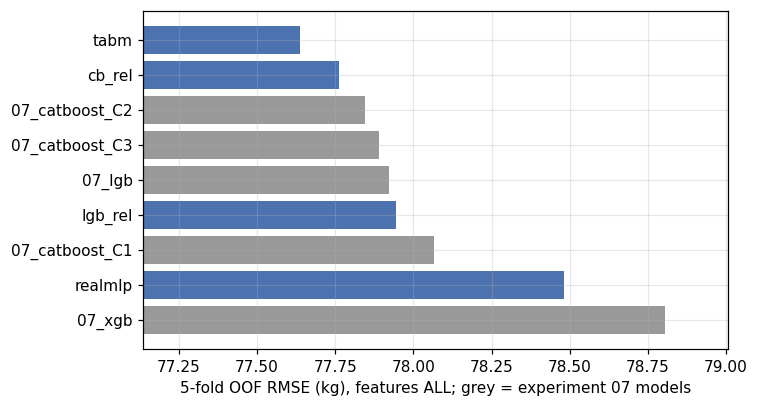

Trois méthodes de stacking évaluées sur cinq plis :


,nested_oof_rmse,fold1,fold2,fold3,fold4,fold5
global_nnls,77.013,77.094,77.201,77.318,77.082,76.365
segment_nnls,77.017,77.098,77.172,77.335,77.112,76.364
residual_meta,77.098,77.173,77.266,77.385,77.199,76.462


In [11]:
def show_zoo():
    directory = ARTIFACTS / '03_model_selection' / 'model_zoo'
    models = read_summary(directory / 'summary_models.csv')
    print('RMSE individuelle et gain dans l’ensemble (préfixe 07_ : expérience 07) :')
    show(models, ['oof_rmse', 'corr_with_07_blend', 'blend_with_07', 'delta_vs_07_blend', 'folds_better'])
    if models is not None:
        ordered = models.sort_values('oof_rmse', ascending=False)
        fig, ax = plt.subplots(figsize=(7, 3.8))
        ax.barh(range(len(ordered)), ordered['oof_rmse'],
                color=['#999999' if n.startswith('07_') else '#4c72b0' for n in ordered.index])
        ax.set_yticks(range(len(ordered)))
        ax.set_yticklabels(ordered.index.tolist())
        ax.set_xlim(ordered['oof_rmse'].min() - 0.5, ordered['oof_rmse'].max() + 0.2)
        ax.set_xlabel('5-fold OOF RMSE (kg), features ALL; grey = experiment 07 models')
        plt.tight_layout()
        plt.show()
    print('Trois méthodes de stacking évaluées sur cinq plis :')
    show(read_summary(directory / 'summary_stacking.csv'))


show_zoo()

TabM est le meilleur modèle seul (**77.636**) et fait gagner 0.15 kg à la combinaison, sur les 5 plis. Le CatBoost DOTS gagne 0.06 kg, RealMLP 0.07 kg (mais 15 minutes par pli), le LightGBM DOTS 0.04 kg. Les trois façons de combiner se valent ; on garde la plus simple, le NNLS global (poids positifs, sans constante, somme libre).

## 4. Cibles alternatives (expérience 14)

Deux autres barèmes que DOTS : une cible **allométrique** (total ÷ poids^(2/3)) et **IPF GL**, dont les coefficients dépendent du sexe et de l'équipement (Raw et Wraps comptent comme « sans équipement »). Même pondération et même retour en kg. L'entraînement se fait avec la quatrième série du notebook 02.

In [12]:
print('Cibles alternatives : variables finales, graine 42, cinq plis ; gain dans LightGBM, XGBoost et CatBoost sur cible DOTS')
show(read_summary(ARTIFACTS / '02_feature_engineering' / CACHE_PERFORMANCE_ABLATION / 'summary_target_engineering.csv'))

Cibles alternatives : variables finales, graine 42, cinq plis ; gain dans LightGBM, XGBoost et CatBoost sur cible DOTS


,oof,corr_with_cb_rel,blend_delta_nested,folds_better
model,,,,
LightGBM,77.709,NaN,NaN,NaN
XGBoost,78.458,NaN,NaN,NaN
CatBoost DOTS,77.160,NaN,NaN,NaN
CatBoost allométrique,77.327,0.997,-0.043,5.0
CatBoost IPF GL,77.162,0.998,-0.076,5.0


**Le CatBoost IPF GL fait 77.162**, autant que le CatBoost DOTS (77.160), avec une corrélation de 0.9975 entre les deux. Pourtant il fait gagner 0.076 kg à la combinaison sur les 5 plis : on le garde. La cible allométrique gagne 0.043 kg, sous le seuil.

## 5. Grande comparaison (expérience 13)

Tous les modèles reçoivent les 57 variables communes et les cinq plis de la graine 42. On regarde le score seul, puis ce que le modèle apporte quand on l'ajoute aux six modèles de l'expérience 11. Un modèle moyen seul peut être utile s'il se trompe autrement que les autres.

MLP-PLR et ResNet n'ont pas tourné (il manquait la dépendance skorch).

In [13]:
if TRAIN['model_compare']:
    ensure_training_env()
    # Comparaison élargie des familles de modèles ; ancien dossier : artifacts/model_compare_v1
    OUTPUT_DIR = ARTIFACTS / '03_model_selection' / 'model_compare'
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    SEEDS = [42, 7, 2024]                      # Chaque graine change les plis, l’early stopping et l’aléa du modèle
    FINAL_MODELS = [MODEL_LIGHTGBM, MODEL_XGBOOST, MODEL_LIGHTGBM_DOTS, MODEL_CATBOOST_ABSOLUTE, MODEL_CATBOOST_DOTS, 'tabm']   # Modèles rapides en premier dans chaque pli
    FULL_REFIT = True                          # Refit des arbres sur tout le train
    REFIT_FACTOR = 1.2                         # Itérations de refit = moyenne CV × 1.2 (environ 39 % de données en plus)

    PREV_DIR = ARTIFACTS / '04_final_model' / 'v1_six_models'     # Résultats de l’expérience 11
    BOOST_DIR = ARTIFACTS / '04_final_model' / 'v2_more_seeds'    # Résultats de l’expérience 12
    PREV_SEEDS = [42, 7, 2024]
    COMPARE = ['ridge', 'hgb', 'et', 'rf', 'tabpfn', 'mlp_plr', 'resnet', 'ebm']   # Les plus rapides en premier
    OPTIONAL = []                         # Options : 'ftt' (lent), 'tabr' (faiss requis)
    TABPFN_CONTEXT_ROWS = 10000           # Contexte TabPFN v2 limité à 10 000 lignes
    ADD_DELTA = -0.02                     # Seuil pour l’ensemble : ΔRMSE ≤ −0.02 sur ≥ 4/5 plis
    TABPFN_TOKEN = os.environ.get('TABPFN_TOKEN')
    if not TABPFN_TOKEN and drive is not None:
        try:
            from google.colab import userdata
            TABPFN_TOKEN = userdata.get('TABPFN_TOKEN')
        except Exception:
            TABPFN_TOKEN = None
    if TABPFN_TOKEN:
        os.environ['TABPFN_TOKEN'] = TABPFN_TOKEN
    print('TabPFN：', 'Version récente (TABPFN_TOKEN fourni)' if TABPFN_TOKEN else 'v2 (sans connexion)')
    if not (PREV_DIR / 'summary_weights.csv').is_file():
        raise FileNotFoundError(f'Résultats de l’expérience 11 absents : {PREV_DIR}')
    # ---- Final features: Variables finales par modèle from experiment 10----
    _CAREER_FRAMES.clear()
    CAREER_VARIANTS[VARIANT_FINAL_FEATURES] = [BLOCK_ATHLETE_CAREER, BLOCK_MEET_EXPERIENCE, BLOCK_MODEL_SPECIFIC]
    FAMILY = {MODEL_LIGHTGBM: MODEL_LIGHTGBM, MODEL_LIGHTGBM_DOTS: MODEL_LIGHTGBM, 'tabm': MODEL_LIGHTGBM, MODEL_XGBOOST: MODEL_XGBOOST, MODEL_CATBOOST_ABSOLUTE: MODEL_CATBOOST_ABSOLUTE, MODEL_CATBOOST_DOTS: MODEL_CATBOOST_ABSOLUTE}
    FRAMES = {m: career_feature_frames(VARIANT_FINAL_FEATURES, FAMILY[m]) for m in FINAL_MODELS}
    for m, (Xtr_m, Xte_m, cats_m) in FRAMES.items():
        print(f'{m:9s} {Xtr_m.shape[1]} columns ({len(cats_m)} categorical), blocks: {feature_blocks_for_model(VARIANT_FINAL_FEATURES, FAMILY[m])}')


    LGB_PARAMS = dict(learning_rate=0.05, num_leaves=63, min_child_samples=40, subsample=0.8, subsample_freq=1,
                      colsample_bytree=0.8, cat_smooth=20, verbose=-1)
    XGB_PARAMS = dict(learning_rate=0.03, max_depth=8, min_child_weight=10.0, subsample=0.8, colsample_bytree=0.7,
                      reg_lambda=1.0, tree_method='hist', device='cuda', enable_categorical=True,
                      max_cat_to_onehot=1, eval_metric='rmse')
    CB_PARAMS = dict(learning_rate=0.05, depth=8, l2_leaf_reg=10.0, bootstrap_type='Bernoulli', subsample=0.8,
                     border_count=128)
    TABM_PARAMS = dict(device='cuda', n_cv=1, n_refit=0, verbosity=0, num_emb_type='pwl')
    TABM_FALLBACK = dict(device='cuda', n_cv=1, n_refit=0, verbosity=0)
    PATIENCE = {MODEL_LIGHTGBM: 200, MODEL_LIGHTGBM_DOTS: 200, MODEL_XGBOOST: 200, MODEL_CATBOOST_ABSOLUTE: 300, MODEL_CATBOOST_DOTS: 300}
    GBDT = [m for m in FINAL_MODELS if m != 'tabm']

    SCALE = dots_scale(train['Sex'], train['BodyweightKg'])           # dots_scale is defined in the experiment 09 features.
    SCALE_TEST = dots_scale(test['Sex'], test['BodyweightKg'])
    require(min(SCALE.min(), SCALE_TEST.min()) > 0.3, 'Invalid DOTS scale')

    X_NN, XT_NN, CATS_NN = FRAMES['tabm']
    NUM_NN = [c for c in X_NN.columns if c not in CATS_NN]
    NAN_NN = [c for c in NUM_NN if X_NN[c].isna().any() or XT_NN[c].isna().any()]


    def target_and_weight(model, rows):
        if model.endswith('_rel'):
            return y[rows] / SCALE[rows], SCALE[rows] ** 2       # Relative error * scale = error in kg
        return y[rows], None


    def gbdt_fit(model, seed, Xa, ya, wa, Xs=None, ys=None, ws=None, rounds=MAX_ROUNDS):
        """No early stopping when Xs is None. Return (model, best iteration)."""
        cats = FRAMES[model][2]
        if model in (MODEL_LIGHTGBM, MODEL_LIGHTGBM_DOTS):
            m = lgb.LGBMRegressor(n_estimators=rounds, random_state=seed, n_jobs=-1, **LGB_PARAMS)
            if Xs is None:
                m.fit(Xa, ya, sample_weight=wa)
                return m, rounds
            m.fit(Xa, ya, sample_weight=wa, eval_set=[(Xs, ys)], eval_sample_weight=None if ws is None else [ws],
                  callbacks=[lgb.early_stopping(PATIENCE[model], verbose=False)])
            return m, int(m.best_iteration_ or rounds)
        if model == MODEL_XGBOOST:
            if Xs is None:
                m = xgb.XGBRegressor(n_estimators=rounds, random_state=seed, **XGB_PARAMS)
                m.fit(Xa, ya, verbose=False)
                return m, rounds
            m = xgb.XGBRegressor(n_estimators=rounds, random_state=seed, early_stopping_rounds=PATIENCE[MODEL_XGBOOST],
                                 **XGB_PARAMS)
            m.fit(Xa, ya, eval_set=[(Xs, ys)], verbose=False)
            return m, int(m.best_iteration) + 1
        common = dict(iterations=rounds, loss_function='RMSE', eval_metric='RMSE', random_seed=seed, verbose=0,
                      task_type='GPU', devices='0', allow_writing_files=False, **CB_PARAMS)
        if Xs is None:
            m = catboost.CatBoostRegressor(**common)
            m.fit(catboost.Pool(Xa, ya, cat_features=cats, weight=wa))
            return m, rounds
        m = catboost.CatBoostRegressor(od_type='Iter', od_wait=PATIENCE[model], **common)
        m.fit(catboost.Pool(Xa, ya, cat_features=cats, weight=wa),
              eval_set=catboost.Pool(Xs, ys, cat_features=cats, weight=ws), use_best_model=True)
        return m, int(m.get_best_iteration()) + 1


    def gbdt_predict(model, m, best, X):
        if model in (MODEL_LIGHTGBM, MODEL_LIGHTGBM_DOTS):
            return m.predict(X, num_iteration=best)
        if model == MODEL_XGBOOST:
            return m.predict(X, iteration_range=(0, best))
        return m.predict(X)


    def nn_frames(*frames):
        """Impute from the first fitting frame and add missingness flags; keep category dtype."""
        median = frames[0][NUM_NN].median()
        out = []
        for frame in frames:
            z = frame.copy()
            for c in NAN_NN:
                z[f'{c}_isna'] = z[c].isna().astype('float64')
            z[NUM_NN] = z[NUM_NN].fillna(median).fillna(0.0)
            out.append(z.reset_index(drop=True))
        return out


    def tabm_fit_predict(seed, a, s, v, Xt, overrides=None):
        require(TabM_D_Regressor is not None, f'pytabkit unavailable: {PYTABKIT_ERROR}')
        params = dict(TABM_PARAMS, random_state=seed, **(overrides or {}))
        unknown = set(params) - set(inspect.signature(TabM_D_Regressor.__init__).parameters)
        require(not unknown, f'TabM does not support parameters {sorted(unknown)}')
        Za, Zs, Zv, Zt = nn_frames(X_NN.iloc[a], X_NN.iloc[s], X_NN.iloc[v], Xt)
        mu, sd = y[a].mean(), y[a].std()
        m = TabM_D_Regressor(**params)
        m.fit(Za, (y[a] - mu) / sd, Zs, (y[s] - mu) / sd, cat_col_names=[c for c in Za.columns if c in CATS_NN])
        p_val = np.asarray(m.predict(Zv), dtype='float64').reshape(-1) * sd + mu
        p_test = np.asarray(m.predict(Zt), dtype='float64').reshape(-1) * sd + mu
        del m
        gc.collect()
        torch.cuda.empty_cache()
        return p_val, p_test


    def fit_fold(model, seed, a, s, v, test_rows=None, rounds=MAX_ROUNDS, overrides=None):
        """a / s / v: inner fitting / early-stopping / outer validation indices. Return (validation predictions, test predictions, best iteration or None)."""
        Xtr, Xte, _ = FRAMES[model]
        Xt = Xte if test_rows is None else Xte.iloc[test_rows]
        scale_t = SCALE_TEST if test_rows is None else SCALE_TEST[test_rows]
        if model == 'tabm':
            p_val, p_test = tabm_fit_predict(seed, a, s, v, Xt, overrides)
            return p_val, p_test, None
        ya, wa = target_and_weight(model, a)
        ys, ws = target_and_weight(model, s)
        if wa is not None:
            norm = wa.mean()
            wa, ws = wa / norm, ws / norm
        m, best = gbdt_fit(model, seed, Xtr.iloc[a], ya, wa, Xtr.iloc[s], ys, ws, rounds)
        p_val, p_test = gbdt_predict(model, m, best, Xtr.iloc[v]), gbdt_predict(model, m, best, Xt)
        if model.endswith('_rel'):
            p_val, p_test = np.asarray(p_val) * SCALE[v], np.asarray(p_test) * scale_t
        return np.asarray(p_val, dtype='float64'), np.asarray(p_test, dtype='float64'), best


    def fit_full(model, seed, rounds, test_rows=None):
        """Fit all rows for a fixed number of iterations; return test predictions."""
        Xtr, Xte, _ = FRAMES[model]
        Xt = Xte if test_rows is None else Xte.iloc[test_rows]
        scale_t = SCALE_TEST if test_rows is None else SCALE_TEST[test_rows]
        rows = np.arange(n_train)
        ya, wa = target_and_weight(model, rows)
        if wa is not None:
            wa = wa / wa.mean()
        m, _ = gbdt_fit(model, seed, Xtr, ya, wa, rounds=rounds)
        p_test = gbdt_predict(model, m, rounds, Xt)
        if model.endswith('_rel'):
            p_test = np.asarray(p_test) * scale_t
        return np.asarray(p_test, dtype='float64')


    from sklearn.compose import ColumnTransformer
    from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor, RandomForestRegressor
    from sklearn.impute import SimpleImputer
    from sklearn.linear_model import Ridge
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

    X_BASE, XT_BASE, CATS = FRAMES[MODEL_LIGHTGBM]            # Référence avec historique + Carrière approchée du sportif + Expérience du plateau; category dtype, as for TabM
    NUMS = [c for c in X_BASE.columns if c not in CATS]
    PYTABKIT_CLASSES = {'mlp_plr': 'MLP_PLR_D_Regressor', 'resnet': 'Resnet_RTDL_D_Regressor',
                        'ftt': 'FTT_D_Regressor', 'tabr': 'TabR_S_D_Regressor'}


    def numeric_with_codes(enc, X, fill=None):
        num = X[NUMS].to_numpy(dtype='float64')
        if fill is not None:
            num = np.where(np.isnan(num), fill, num)
        return np.hstack([num, enc.transform(X[CATS])])


    def fit_ridge(seed, a, s, v, Xt, small=False):
        rows = np.concatenate([a, s])
        pre = ColumnTransformer([
            ('num', make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler()), NUMS),
            ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=20), CATS)])
        model = make_pipeline(pre, Ridge(alpha=10.0)).fit(X_BASE.iloc[rows], y[rows])
        return model.predict(X_BASE.iloc[v]), model.predict(Xt)


    def fit_hgb(seed, a, s, v, Xt, small=False):
        rows = np.concatenate([a, s])
        enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan, encoded_missing_value=np.nan,
                             max_categories=250).fit(X_BASE.iloc[rows][CATS])
        mask = [False] * len(NUMS) + [True] * len(CATS)
        model = HistGradientBoostingRegressor(
            categorical_features=mask, learning_rate=0.05, max_iter=20 if small else 3000, max_leaf_nodes=63,
            min_samples_leaf=40, l2_regularization=1.0, early_stopping=True, validation_fraction=0.1,
            n_iter_no_change=100, random_state=seed)
        model.fit(numeric_with_codes(enc, X_BASE.iloc[rows]), y[rows])           # 10% internal early-stopping split
        return model.predict(numeric_with_codes(enc, X_BASE.iloc[v])), model.predict(numeric_with_codes(enc, Xt))


    def fit_forest(kind, seed, a, s, v, Xt, small=False):
        rows = np.concatenate([a, s])
        enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1).fit(X_BASE.iloc[rows][CATS])
        common = dict(n_estimators=10 if small else 200, min_samples_leaf=5, n_jobs=-1, random_state=seed)
        model = (RandomForestRegressor(max_features=0.3, max_samples=0.5, **common) if kind == MODEL_RANDOM_FOREST
                 else ExtraTreesRegressor(max_features=0.5, **common))
        model.fit(numeric_with_codes(enc, X_BASE.iloc[rows], fill=-999.0), y[rows])
        return (model.predict(numeric_with_codes(enc, X_BASE.iloc[v], fill=-999.0)),
                model.predict(numeric_with_codes(enc, Xt, fill=-999.0)))


    def fit_ebm(seed, a, s, v, Xt, small=False):
        from interpret.glassbox import ExplainableBoostingRegressor
        rows = np.concatenate([a, s])
        model = ExplainableBoostingRegressor(interactions=0 if small else 5, outer_bags=1 if small else 2,
                                             max_rounds=50 if small else 5000, n_jobs=-1, random_state=seed)
        model.fit(X_BASE.iloc[rows], y[rows])                                   # Internal validation split for early stopping
        return np.asarray(model.predict(X_BASE.iloc[v])), np.asarray(model.predict(Xt))


    def make_tabpfn():
        from tabpfn import TabPFNRegressor
        if TABPFN_TOKEN:
            return TabPFNRegressor(device='cuda', ignore_pretraining_limits=True)
        from tabpfn.constants import ModelVersion
        return TabPFNRegressor.create_default_for_version(ModelVersion.V2)


    def fit_tabpfn(seed, a, s, v, Xt, small=False):
        rows = np.concatenate([a, s])
        context = np.random.default_rng(seed).choice(rows, size=min(500 if small else TABPFN_CONTEXT_ROWS, len(rows)),
                                                     replace=False)
        enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan,
                             encoded_missing_value=np.nan).fit(X_BASE.iloc[context][CATS])
        model = make_tabpfn()
        model.fit(numeric_with_codes(enc, X_BASE.iloc[context]), y[context])
        p_val = np.asarray(model.predict(numeric_with_codes(enc, X_BASE.iloc[v])), dtype='float64')
        p_test = np.asarray(model.predict(numeric_with_codes(enc, Xt)), dtype='float64')
        del model
        gc.collect()
        torch.cuda.empty_cache()
        return p_val, p_test


    def fit_pytabkit(name, seed, a, s, v, Xt, small=False):
        if name == 'tabr':
            subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'faiss-cpu'], check=False)
        import pytabkit
        cls = getattr(pytabkit, PYTABKIT_CLASSES[name])
        params = dict(device='cuda', random_state=seed, n_cv=1, n_refit=0, verbosity=0)
        if small:
            params['max_epochs'] = 2
        unknown = set(params) - set(inspect.signature(cls.__init__).parameters)
        require(not unknown, f'{name} does not support parameters {sorted(unknown)}')
        Za, Zs, Zv, Zt = nn_frames(X_NN.iloc[a], X_NN.iloc[s], X_NN.iloc[v], Xt)    # Same imputation as TabM
        mu, sd = y[a].mean(), y[a].std()
        m = cls(**params)
        m.fit(Za, (y[a] - mu) / sd, Zs, (y[s] - mu) / sd, cat_col_names=[c for c in Za.columns if c in CATS_NN])
        p_val = np.asarray(m.predict(Zv), dtype='float64').reshape(-1) * sd + mu
        p_test = np.asarray(m.predict(Zt), dtype='float64').reshape(-1) * sd + mu
        del m
        gc.collect()
        torch.cuda.empty_cache()
        return p_val, p_test


    def fit_new(name, seed, a, s, v, Xt, small=False):
        if name == 'ridge':
            return fit_ridge(seed, a, s, v, Xt, small)
        if name == MODEL_HISTOGRAM_GRADIENT_BOOSTING:
            return fit_hgb(seed, a, s, v, Xt, small)
        if name in (MODEL_RANDOM_FOREST, MODEL_EXTRA_TREES):
            return fit_forest(name, seed, a, s, v, Xt, small)
        if name == 'ebm':
            return fit_ebm(seed, a, s, v, Xt, small)
        if name == 'tabpfn':
            return fit_tabpfn(seed, a, s, v, Xt, small)
        return fit_pytabkit(name, seed, a, s, v, Xt, small)


    def save_result(stem, arrays, info):
        np.savez(OUTPUT_DIR / f'{stem}.npz', **arrays)
        info = {**info, 'gpu': GPU_NAME, 'versions': VERSIONS, 'finished_at_utc': datetime.now(timezone.utc).isoformat()}
        (OUTPUT_DIR / f'{stem}.json').write_text(json.dumps(info, ensure_ascii=False, indent=1), encoding='utf-8')
        return info


    # Smoke check on 3,000 rows with a small budget; skip failed candidates.
    rng = np.random.default_rng(SEED)
    probe = rng.choice(n_train, 3000, replace=False)
    pa, ps, pv = probe[:2000], probe[2000:2500], probe[2500:]
    failed = {}
    for name in COMPARE + OPTIONAL:
        started = time.perf_counter()
        try:
            p_val, p_test = fit_new(name, SEED, pa, ps, pv, XT_BASE.iloc[:300], small=True)
            p_val, p_test = np.asarray(p_val, dtype='float64'), np.asarray(p_test, dtype='float64')
            require(len(p_val) == len(pv) and len(p_test) == 300, 'Prediction length mismatch')
            require(np.isfinite(p_val).all() and np.isfinite(p_test).all(), 'Non-finite predictions')
            print(f'Smoke check passed: {name:8s} RMSE (small budget) {rmse(y[pv], p_val):.1f}, elapsed  {time.perf_counter() - started:.0f}s')
        except Exception as exc:
            failed[name] = repr(exc)
            print(f'Smoke check failed, skipping: {name} → {exc!r}')
    RUN_NEW = [n for n in COMPARE + OPTIONAL if n not in failed]
    print('Candidates: ', RUN_NEW)


    def run_new(name, fold):
        stem = f'{name}__s{SEED}__fold{fold}'
        json_path, npz_path = OUTPUT_DIR / f'{stem}.json', OUTPUT_DIR / f'{stem}.npz'
        if json_path.is_file() and npz_path.is_file():
            return json.loads(json_path.read_text(encoding='utf-8')), 'cache'
        fit_idx, valid_idx = np.flatnonzero(FOLD_IDS != fold), np.flatnonzero(FOLD_IDS == fold)
        inner_fit, inner_stop = train_test_split(fit_idx, test_size=INNER_STOP_FRACTION, random_state=SEED)  # = 11
        started = time.perf_counter()
        p_val, p_test = fit_new(name, SEED, inner_fit, inner_stop, valid_idx, XT_BASE)
        p_val, p_test = np.asarray(p_val, dtype='float64'), np.asarray(p_test, dtype='float64')
        require(np.isfinite(p_val).all() and np.isfinite(p_test).all(), f'{stem} Non-finite predictions')
        info = save_result(stem, {'valid_idx': valid_idx, 'val': p_val, 'test': p_test},
                           {'model': name, 'fold': fold, 'rmse': rmse(y[valid_idx], p_val),
                            'seconds': time.perf_counter() - started})
        return info, f'{info["seconds"]:.0f}s'


    for name in RUN_NEW:
        started = time.perf_counter()
        try:
            for fold in range(1, N_FOLDS + 1):
                info, how = run_new(name, fold)
                print(f'{name:8s} fold {fold}  RMSE {info["rmse"]:.3f}  ({how})')
            print(f'—— {name} finished; elapsed {(time.perf_counter() - started) / 60:.1f} min')
        except Exception as exc:
            print(f'!! {name} failed; skipping remaining folds: {exc!r}')


    def load_folds(directory, stem_prefix):
        oof, test_pred = np.full(n_train, np.nan), np.zeros(len(test))
        for fold in range(1, N_FOLDS + 1):
            path = directory / f'{stem_prefix}__fold{fold}.npz'
            if not path.is_file():
                return None
            saved = np.load(path)
            oof[saved['valid_idx']] = saved['val']
            test_pred += saved['test'] / N_FOLDS
        return oof, test_pred


    def fold_rmse(pred):
        return np.array([rmse(y[FOLD_IDS == k], pred[FOLD_IDS == k]) for k in range(1, N_FOLDS + 1)])


    def nested_nnls(oof_prediction_matrix):
        out = np.zeros(n_train)
        for k in range(1, N_FOLDS + 1):
            fit, va = FOLD_IDS != k, FOLD_IDS == k
            w, _ = nnls(oof_prediction_matrix[fit], y[fit])
            out[va] = oof_prediction_matrix[va] @ w
        return out


    # Experiment 11: seed-42 OOF for individual comparisons, three-seed OOF for blending, selected test predictions.
    BASE = {}
    for model in FINAL_MODELS:
        per_seed = {s: load_folds(PREV_DIR, f'{model}__s{s}') for s in PREV_SEEDS}
        require(all(v is not None for v in per_seed.values()), f'Experiment 11 is missing {model} results')
        fulls = [np.load(p)['test'] for d in (PREV_DIR, BOOST_DIR) if d.is_dir() for p in sorted(d.glob(f'{model}__s*__full.npz'))]
        near = [np.load(p)['test'] for p in sorted(BOOST_DIR.glob('tabm__s*__nearfull.npz'))] if BOOST_DIR.is_dir() else []
        fold_avg = np.mean([t for _, t in per_seed.values()], axis=0)
        best_test = np.mean(fulls, axis=0) if fulls else (np.mean(near, axis=0) if (model == 'tabm' and near) else fold_avg)
        BASE[model] = {'oof42': per_seed[42][0], 'oof': np.mean([o for o, _ in per_seed.values()], axis=0),
                       'test': best_test}
    NEW = {}
    for name in COMPARE + OPTIONAL:
        loaded = load_folds(OUTPUT_DIR, f'{name}__s{SEED}')
        if loaded is not None:
            NEW[name] = {'oof42': loaded[0], 'oof': loaded[0], 'test': loaded[1]}

    base_names = list(BASE)
    P_base = np.column_stack([BASE[m]['oof'] for m in base_names])
    base_nested = nested_nnls(P_base)
    base_folds = fold_rmse(base_nested)
    rows = []
    for name, item in {**BASE, **NEW}.items():
        row = {'model': name, 'source': '11' if name in BASE else '13', 'oof_seed42': rmse(y, item['oof42']),
               'corr_with_blend': float(np.corrcoef(item['oof42'], base_nested)[0, 1])}
        if name in NEW:
            oof_prediction_matrix = np.column_stack([P_base, item['oof']])
            nested = nested_nnls(oof_prediction_matrix)
            delta = fold_rmse(nested) - base_folds
            w, _ = nnls(oof_prediction_matrix, y)
            row.update({'blend_nested': rmse(y, nested), 'delta_vs_blend': rmse(y, nested) - rmse(y, base_nested),
                        'folds_better': int((delta < 0).sum()), 'weight_in_blend': float(w[-1])})
        rows.append(row)
    compare = pd.DataFrame(rows).set_index('model').sort_values('oof_seed42')
    print(f'Experiment 11, six-model blend (cross-fitted weights): {rmse(y, base_nested):.3f}')
    display(compare.round(3))
    compare.to_csv(OUTPUT_DIR / 'summary_compare.csv')
    seconds = {}
    for p in OUTPUT_DIR.glob('*__fold*.json'):
        info = json.loads(p.read_text(encoding='utf-8'))
        seconds.setdefault(info['model'], []).append(info['seconds'])
    print('Mean seconds per fold: ', {k: round(float(np.mean(v))) for k, v in seconds.items()})

    KEEP_NEW = [n for n in NEW if compare.loc[n, 'delta_vs_blend'] <= ADD_DELTA and compare.loc[n, 'folds_better'] >= 4]
    print('New models meeting the selection rule: ', KEEP_NEW or 'none')


    if KEEP_NEW:
        names = base_names + KEEP_NEW
        ITEMS = {**BASE, **{n: NEW[n] for n in KEEP_NEW}}
        P_all = np.column_stack([ITEMS[n]['oof'] for n in names])
        WEIGHTS_PLUS, _ = nnls(P_all, y)
        NESTED = nested_nnls(P_all)
        BLEND_TEST = {ENSEMBLE_WITH_HISTOGRAM_BOOSTING: np.column_stack([ITEMS[n]['test'] for n in names]) @ WEIGHTS_PLUS}
        print('Weights: ', dict(zip(names, WEIGHTS_PLUS.round(3))))
        print(f'Blend with cross-fitted weights: {rmse(y, base_nested):.3f} → {rmse(y, NESTED):.3f}')
    else:
        NESTED, BLEND_TEST = None, None
        print('No new model meets the selection rule; retain the experiment 11 / 12 submission.')


    if BLEND_TEST is not None:
        CORE = CORE9


        def row_keys(frame, columns):
            return pd.util.hash_pandas_object(frame[columns], index=False).to_numpy()


        def matching_group_statistics(train_keys, query_keys=None):
            table = pd.DataFrame({'k': train_keys, 'y': y}).groupby('k')['y'].agg(['sum', 'count'])
            if query_keys is None:                      # Training rows: leave one out
                keys = pd.Series(train_keys)
                n = keys.map(table['count']).to_numpy() - 1
                s = keys.map(table['sum']).to_numpy() - y
            else:                                       # Test rows: use all training rows
                keys = pd.Series(query_keys)
                n = keys.map(table['count']).fillna(0).to_numpy()
                s = keys.map(table['sum']).fillna(0).to_numpy()
            return n, np.where(n > 0, s / np.maximum(n, 1), np.nan)


        def matching_record_statistics(query_exact=None, query_core=None):
            n_ex, m_ex = matching_group_statistics(row_keys(train, RAW_FEATURES), query_exact)
            n_co, m_co = matching_group_statistics(row_keys(train, CORE), query_core)
            level = np.select([n_ex > 0, n_co > 0], ['exact', 'core'], default='none')
            return level, np.where(level == 'exact', m_ex, m_co)


        def fit_alpha(mask, pred, mate):
            d = mate[mask] - pred[mask]
            denom = float(np.sum(d * d))
            return float(np.clip(np.sum((y[mask] - pred[mask]) * d) / denom, 0, 1)) if denom > 0 else 0.0


        def apply_matching_correction(pred, mate, level, alphas):
            out = pred.copy()
            for lv, a in alphas.items():
                m = level == lv
                out[m] = pred[m] + a * (mate[m] - pred[m])
            return out


        LEVEL, MATE = matching_record_statistics()
        T_LEVEL, T_MATE = matching_record_statistics(row_keys(test, RAW_FEATURES), row_keys(test, CORE))
        HALF = (pd.util.hash_pandas_object(train[['Sex', 'Country', 'State']], index=False).to_numpy() % 2).astype(int)
        TR, TE = train.reset_index(drop=True), test.reset_index(drop=True)


        def text_key(frame, columns):
            out = frame[columns[0]].astype(str)
            for c in columns[1:]:
                out = out + '|' + frame[c].astype(str)
            return out


        BY_TR = np.floor(TR['MeetYear'] - TR['Age'] + 1e-9).astype(int)
        BY_TE = np.floor(TE['MeetYear'] - TE['Age'] + 1e-9).astype(int)
        YR_TR, YR_TE = TR['MeetYear'].astype(int), TE['MeetYear'].astype(int)
        RESIDUAL_MATCH_COLUMNS = {MATCH_RESIDENCE: ['Sex', 'Country', 'State'], MATCH_FEDERATION: ['Sex', 'Country', 'State', 'Federation'],
                  MATCH_EQUIPMENT: ['Sex', 'Country', 'State', 'Federation', 'Equipment'],
                  MATCH_WEIGHT_CLASS: ['Sex', 'Country', 'State', 'Federation', 'Equipment', 'WeightClassKg']}
        RESIDUAL_SHRINKAGE = {MATCH_RESIDENCE: 5.0, MATCH_FEDERATION: 5.0, MATCH_EQUIPMENT: 3.0, MATCH_WEIGHT_CLASS: 2.0}
        PFX_TR = {k: text_key(TR, c) for k, c in RESIDUAL_MATCH_COLUMNS.items()}
        PFX_TE = {k: text_key(TE, c) for k, c in RESIDUAL_MATCH_COLUMNS.items()}
        MEET_COLS = ['Federation', 'MeetYear', 'MeetCountry', 'MeetState', 'Sex', 'Equipment']
        MEET_TR, MEET_TE = text_key(TR, MEET_COLS), text_key(TE, MEET_COLS)
        VALID_TR = (TR['Country'] != 'Unknown').to_numpy(dtype='float64')
        VALID_TE = (TE['Country'] != 'Unknown').to_numpy(dtype='float64')


        def sums(keys, values):
            table = pd.DataFrame({'k': keys.to_numpy(), 'v': values}).groupby('k')['v'].agg(['sum', 'count'])
            return table['sum'], table['count']


        def look(table, keys):
            s, n = table
            return keys.map(s).fillna(0).to_numpy(dtype='float64'), keys.map(n).fillna(0).to_numpy(dtype='float64')


        def exact_birthyear_residuals(k, r):
            ktr, kte = PFX_TR[k] + '|' + BY_TR.astype(str), PFX_TE[k] + '|' + BY_TE.astype(str)
            table = sums(ktr, r)
            s, n = look(table, ktr)
            st, nt = look(table, kte)
            return (s - r) / (n - 1 + RESIDUAL_SHRINKAGE[k]), st / (nt + RESIDUAL_SHRINKAGE[k])


        def nearby_birthyear_residuals(k, r):
            table = sums(PFX_TR[k] + '|' + BY_TR.astype(str), r)
            s, n, st, nt = np.zeros(n_train), np.zeros(n_train), np.zeros(len(TE)), np.zeros(len(TE))
            for d in (-1, 0, 1):
                a, b = look(table, PFX_TR[k] + '|' + (BY_TR + d).astype(str))
                s, n = s + a, n + b
                a, b = look(table, PFX_TE[k] + '|' + (BY_TE + d).astype(str))
                st, nt = st + a, nt + b
            return (s - r) / (n - 1 + RESIDUAL_SHRINKAGE[k]), st / (nt + RESIDUAL_SHRINKAGE[k])


        def temporal_residuals(k, r, tau=3.0, max_gap=8):
            base_tr = PFX_TR[k] + '|' + BY_TR.astype(str) + '|'
            base_te = PFX_TE[k] + '|' + BY_TE.astype(str) + '|'
            table = sums(base_tr + YR_TR.astype(str), r)
            s, n, st, nt = np.zeros(n_train), np.zeros(n_train), np.zeros(len(TE)), np.zeros(len(TE))
            for d in range(-max_gap, max_gap + 1):
                w = float(np.exp(-abs(d) / tau))
                a, b = look(table, base_tr + (YR_TR + d).astype(str))
                s, n = s + w * a, n + w * b
                a, b = look(table, base_te + (YR_TE + d).astype(str))
                st, nt = st + w * a, nt + w * b
            return (s - r) / (n - 1 + RESIDUAL_SHRINKAGE[k]), st / (nt + RESIDUAL_SHRINKAGE[k])     # At d = 0 the current row has weight 1 and is subtracted.


        def meet_residuals(r, lam=20.0):
            table = sums(MEET_TR, r)
            s, n = look(table, MEET_TR)
            st, nt = look(table, MEET_TE)
            return (s - r) / (n - 1 + lam), st / (nt + lam)


        def residual_neighborhood_features(r):
            cols_tr, cols_te = [], []
            for builder in (exact_birthyear_residuals, nearby_birthyear_residuals, temporal_residuals):
                for k in RESIDUAL_MATCH_COLUMNS:
                    a, b = builder(k, r)
                    cols_tr.append(a * VALID_TR)
                    cols_te.append(b * VALID_TE)
            a, b = meet_residuals(r)
            cols_tr.append(a)
            cols_te.append(b)
            return np.column_stack(cols_tr), np.column_stack(cols_te)


        # Post-processing uses training OOF; reuse coefficients for all three test variants. See the validation caveat in notebook 04.
        alphas = {lv: fit_alpha(LEVEL == lv, NESTED, MATE) for lv in ['exact', 'core']}
        p1 = apply_matching_correction(NESTED, MATE, LEVEL, alphas)
        p1_cf = NESTED.copy()
        for h in (0, 1):
            a_h = {lv: fit_alpha((HALF != h) & (LEVEL == lv), NESTED, MATE) for lv in ['exact', 'core']}
            m = HALF == h
            p1_cf[m] = apply_matching_correction(NESTED[m], MATE[m], LEVEL[m], a_h)
        corrected_residuals = y - p1
        F, FT = residual_neighborhood_features(corrected_residuals)
        p2_cf = p1_cf.copy()
        for h in (0, 1):
            fit, m = HALF != h, HALF == h
            beta_h = np.linalg.lstsq(F[fit], corrected_residuals[fit], rcond=None)[0]
            p2_cf[m] = p1_cf[m] + F[m] @ beta_h
        BETA = np.linalg.lstsq(F, corrected_residuals, rcond=None)[0]
        STAGE2_ADJ = FT @ BETA
        stage_table = pd.DataFrame([{'step': 'Blend (cross-fitted weights)', 'oof_rmse': rmse(y, NESTED)},
                                    {'step': '+ Matched records (cross-fitted coefficients)', 'oof_rmse': rmse(y, p1_cf)},
                                    {'step': SUMMARY_FINAL_SMOOTHING, 'oof_rmse': rmse(y, p2_cf)}]).set_index('step')
        display(stage_table.round(3))
        stage_table.to_csv(OUTPUT_DIR / 'summary_stage2.csv')
        print('alpha: ', {k: round(v, 3) for k, v in alphas.items()}, '| Matched test rows: ', int((T_LEVEL != 'none').sum()),
              '| Correction absolue moyenne du lissage combiné des résidus : ', round(float(np.abs(STAGE2_ADJ).mean()), 2), 'kg')

        for kind, pred in BLEND_TEST.items():
            final = apply_matching_correction(pred, T_MATE, T_LEVEL, alphas) + STAGE2_ADJ
            for stage, values in [('base', pred), ('final', final)]:
                path = OUTPUT_DIR / f'submission_final_{kind}_{stage}.csv'
                pd.DataFrame({'id': test['id'], TARGET: np.clip(values, 0, None)}).to_csv(path, index=False)
                print('Saved', path.name)
        np.save(OUTPUT_DIR / 'oof_nested_blend.npy', NESTED)
        np.save(OUTPUT_DIR / 'oof_final_crossfit.npy', p2_cf)
    print('Done.')
else:
    print("Entraînement désactivé (TRAIN['model_compare'] = False) : lecture des résultats dans artifacts/.")

Entraînement désactivé (TRAIN['model_compare'] = False) : lecture des résultats dans artifacts/.


,source,oof_seed42,corr_with_blend,blend_nested,delta_vs_blend,folds_better,weight_in_blend
model,,,,,,,
CatBoost DOTS,11,77.167,0.997,NaN,NaN,NaN,NaN
tabm,11,77.493,0.996,NaN,NaN,NaN,NaN
CatBoost,11,77.497,0.996,NaN,NaN,NaN,NaN
LightGBM DOTS,11,77.646,0.996,NaN,NaN,NaN,NaN
LightGBM,11,77.709,0.995,NaN,NaN,NaN,NaN
HGB,13,77.881,0.994,76.361,-0.034,5.0,0.147
XGBoost,11,78.458,0.993,NaN,NaN,NaN,NaN
ExtraTrees,13,81.054,0.985,76.395,0.000,0.0,0.000
ebm,13,81.448,0.985,76.395,0.000,0.0,0.000


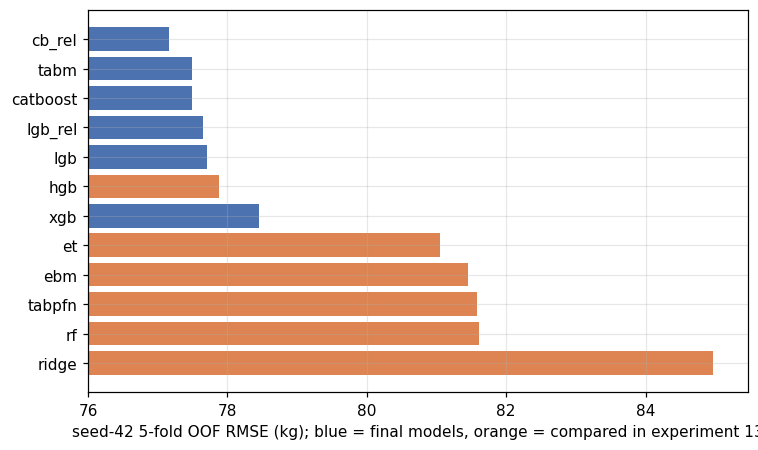

In [14]:
def show_compare():
    compare = read_summary(ARTIFACTS / '03_model_selection' / 'model_compare' / 'summary_compare.csv')
    show(compare, ['source', 'oof_seed42', 'corr_with_blend', 'blend_nested', 'delta_vs_blend', 'folds_better',
                   'weight_in_blend'])
    if compare is not None:
        ordered = compare.sort_values('oof_seed42', ascending=False)
        fig, ax = plt.subplots(figsize=(7, 4.2))
        ax.barh(range(len(ordered)), ordered['oof_seed42'],
                color=['#4c72b0' if s == 11 or str(s) == '11' else '#dd8452' for s in ordered['source']])
        ax.set_yticks(range(len(ordered)))
        ax.set_yticklabels(ordered.index.tolist())
        ax.set_xlim(76, ordered['oof_seed42'].max() + 0.5)
        ax.set_xlabel('seed-42 5-fold OOF RMSE (kg); blue = final models, orange = compared in experiment 13')
        plt.tight_layout()
        plt.show()


show_compare()

Les arbres boostés et TabM sont loin devant. TabPFN, la forêt aléatoire, ExtraTrees, EBM et Ridge sont 3 à 7 kg derrière et reçoivent un poids nul. Seul **HGB** apporte quelque chose : 77.881 seul, −0.034 kg dans la combinaison sur les 5 plis, poids 0.15. La soumission correspondante fait 76.334 au score public.

## 6. Taux d'apprentissage du CatBoost DOTS (expérience 12)

Comparaison 0.03 contre 0.05 sur les cinq plis de la graine 42. L'entraînement se lance avec le bouton `more_seeds` du notebook 04.

In [15]:
lr_check = read_summary(ARTIFACTS / '04_final_model' / CACHE_EXPANDED_SEED_ENSEMBLE / 'summary_lr_check.csv')
show(lr_check)
if lr_check is not None:
    print(f"Learning rate 0.03 vs 0.05 : {lr_check['delta'].mean():+.3f} kg, {int((lr_check['delta'] < 0).sum())}/5 plis améliorés ; "
          f"ratio des meilleures itérations : {lr_check['best_iter_0.03'].mean() / lr_check['best_iter_0.05'].mean():.2f}")

,lr_0.05,lr_0.03,delta,best_iter_0.05,best_iter_0.03,minutes_0.03
fold,,,,,,
1,77.285,77.117,-0.167,3543,3741,2.402
2,77.179,77.061,-0.118,2398,4058,2.613
3,77.550,77.493,-0.057,2263,4949,3.152
4,77.339,77.317,-0.022,2374,2896,1.885
5,76.480,76.494,0.014,2211,2727,1.788


Learning rate 0.03 vs 0.05 : -0.070 kg, 4/5 plis améliorés ; ratio des meilleures itérations : 1.44


Avec 0.03, le gain moyen est de 0.07 kg (4 plis sur 5), pour environ 1.44 fois plus d'itérations. On l'utilise pour les réentraînements des deux CatBoost relatifs.

## 7. Les huit modèles gardés pour la suite

| Modèle | Cible | Réglage |
|---|---|---|
| LightGBM | kg | paramètres de v2 |
| XGBoost | kg | paramètres de v2, GPU |
| CatBoost | kg | profondeur 8, L2 10, Bernoulli 0.8 |
| LightGBM DOTS | score DOTS | comme LightGBM |
| CatBoost DOTS | score DOTS | comme CatBoost |
| CatBoost IPF GL | score IPF GL | comme CatBoost |
| TabM | kg standardisé | pytabkit, embeddings linéaires par morceaux |
| HGB | kg | HistGradientBoosting de scikit-learn, catégories natives |

Leurs poids dans la combinaison sont dans le notebook 04.